# Distribution shift, robustness and statistical analysis
## 1. Introduction and Research Objectives
This notebook evaluates **previously fitted** models on Elliptic steps 35–49. It asks whether graph learning adds predictive value over matched tabular models, how scores change over time, and how frozen models respond to controlled input degradation. No model is fitted, recalibrated or redesigned here.

The three feature groups (18 / 93 / 165) are **not certified leakage-free**. Published features already contain relational information. Metrics condition on known labels, not the full operational review population. Seed variation, temporal sampling uncertainty and source-validity limitations are reported separately.

Run from the repository root or `notebooks/`. The first official evaluation requires `FULL_RUN`. Later executions reuse cached inference and aggregate statistics. `QUICK_RUN` is an exploratory, cached-results review after the official run; it cannot unlock test data first or overwrite official results.

**Stage 5 audit correction (2026-11-09).** The original frozen JSON is unchanged. Release-time cache provenance now validates complete per-scenario probabilities, metrics and edge audits before reuse; committed scenarios restore their edge-audit rows on interrupted runs. The release defaults to cached inference only. Use `python scripts/validate_cache.py` to validate, `--adopt-legacy` once for legacy files with complete evidence, and `--recover-tables` to rebuild aggregates from verified scenario records. Missing predictions are never synthesized. These later checks and the dated release manifest cannot retroactively establish the original notebook/code freeze. Original execution outputs below are retained; the new cache path is separately tested and the guard cells are replayed without model inference.

In [1]:
from pathlib import Path
import os
os.environ["OMP_NUM_THREADS"] = "1"  # Preserve the combined LightGBM/PyTorch threading fix.
import sys, time, json, shutil, platform, importlib.metadata
ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "matplotlib"))

RUN_MODE = "FULL_RUN"
if RUN_MODE not in {"FULL_RUN", "QUICK_RUN"}:
    raise ValueError("Choose FULL_RUN or QUICK_RUN")
QUICK_RUN = RUN_MODE == "QUICK_RUN"
ALLOW_NEW_INFERENCE = False  # Release default: use verified existing caches only.
SEEDS = [42, 43, 44]
PRIMARY_SEED = 42
FEATURE_GROUPS = ["conservative18", "local93", "published165"]
SEVERITIES = [0.1, 0.2, 0.3]
PERTURBATION_SEEDS = [2026, 2027]
BOOTSTRAP_REPETITIONS = 1000
BOOTSTRAP_BLOCK_LENGTH = 3
BOOTSTRAP_SEED = 20261109
REVIEW_K = 25
CALIBRATION_BINS = 10
MIN_CLASS_PER_STEP = 5
CPU_THREADS = 2

import numpy as np
import pandas as pd
import joblib
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import expit
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.calibration import calibration_curve
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown
from src.data import load_elliptic, file_fingerprints, snapshot_summary, feature_groups
from src.baselines import baseline_feature_sets, decision_scores, apply_sigmoid
from src.evaluation import binary_metrics, evaluate_predictions
from src.graph_learning import GraphRiskModel
from src.robustness import (sha256, freeze_protocol, verify_frozen, perturb_features,
    distribution_shift, circular_block_counts, bootstrap_ap, aligned_pair, expected_calibration_error)
from src.frozen_inference import (stage4_snapshots, modified_snapshots, context_before_test,
    infer_test_graphs, test_prediction_frame)

from src.cache_provenance import (audit_stage4_cache, read_committed_scenario,
    validate_scenario_metrics, validate_edge_audit, atomic_csv, commit_scenario)

torch.set_num_threads(CPU_THREADS)
BASE = ROOT / "results" / "stage4"
OFFICIAL = BASE / "full_run"
RESULT_DIR = BASE / ("quick_run" if QUICK_RUN else "full_run")
PRIVATE_DIR = ROOT / "results" / "local" / "stage4" / "full_run"
FIGURE_DIR = ROOT / "reports" / "figures"
if QUICK_RUN:
    if not (OFFICIAL / "execution_summary.json").is_file():
        raise PermissionError("QUICK_RUN uses cached official outputs only; execute FULL_RUN after freezing first")
    FIGURE_DIR = FIGURE_DIR / "exploratory_stage4"
for folder in [RESULT_DIR, PRIVATE_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
started_at = time.perf_counter()
section_times = {}
figure_names = []
NAMES = {"logistic_regression": "Logistic regression", "lightgbm": "LightGBM", "graphsage": "GraphSAGE", "gat": "GAT", "sage_gru": "SAGE + historical GRU"}
SHORT = {"logistic_regression": "LR", "lightgbm": "LGBM", "graphsage": "SAGE", "gat": "GAT", "sage_gru": "SAGE+GRU"}
GROUP_NAMES = {"conservative18": "Conservative 18", "local93": "Published local 93", "published165": "Published non-time 165"}
ARCHITECTURES = list(NAMES)
COLORS = dict(zip(ARCHITECTURES, ["#777777", "#D55E00", "#0072B2", "#009E73", "#CC79A7"]))
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "svg.fonttype": "none", "axes.spines.top": False, "axes.spines.right": False})

def save_figure(fig, name):
    fig.tight_layout()
    for suffix in ["png", "svg"]:
        fig.savefig(FIGURE_DIR / f"{name}.{suffix}", dpi=300, bbox_inches="tight")
    figure_names.append(name)
    plt.show()
    plt.close(fig)

def save_table(table, name):
    table.to_csv(RESULT_DIR / name, index=False)
    return table

def cached_table(name):
    return pd.read_csv(OFFICIAL / name)

def save_progress(section, seconds):
    section_times[section] = round(seconds, 4)
    (RESULT_DIR / "progress.json").write_text(json.dumps({"run_mode": RUN_MODE, "completed_sections": section_times}, indent=2) + "\n")

print(f"{RUN_MODE}; cached exploratory review={QUICK_RUN}; previously selected frozen models; no additional parameter fitting")

FULL_RUN; cached exploratory review=False; previously selected frozen models; no additional parameter fitting


## 2. Experimental Setup and Frozen Protocol
Training was restricted to 1–29; hyperparameters and stopping epochs to 30–31; calibration and operating rules to 32–33; step 34 was later validation only. We reuse the tabular weighting selected on 30–31 and **all three** saved neural seeds, rather than selecting a favorable seed.

Before any test prediction, the next cell writes an immutable manifest containing artifact hashes, feature order, thresholds, calibrators, comparisons, perturbations and bootstrap settings. Primary AP uses uncalibrated probabilities, matching Stages 2–3. Platt-calibrated metrics are reported separately, with their own previously fitted rules. AP is the non-interpolated average precision used by [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html), not trapezoidal PR area.

The bootstrap samples circular blocks of **three adjacent snapshots**, five blocks per replicate, 1,000 paired replicates. Snapshot multiplicities weight the pooled AP; transactions are never resampled independently. Endpoint wrap-around and approximate local stationarity are assumptions, not established properties of this historical release. Intervals are pointwise, descriptive and unadjusted across 12 comparisons; no significance declarations or p-values are planned.

In [2]:
selection_table = pd.read_csv(ROOT / "results/stage2/full_run/selected_models.csv")
selection_table = selection_table.loc[selection_table.feature_configuration.isin(FEATURE_GROUPS)]
chosen_tabular = (selection_table.sort_values("selection_ap", ascending=False, kind="stable")
    .drop_duplicates(["family", "feature_configuration", "seed"]))
neural_config = json.loads((ROOT / "results/stage3/full_run/selected_configurations.json").read_text())
assert neural_config["seeds"] == SEEDS and neural_config["maximum_constructed_snapshot"] == 34
assert not neural_config["final_test_predictions_computed"]
assert neural_config["selection_steps"] == [30, 31] and neural_config["calibration_steps"] == [32, 33]
FEATURE_SETS = {group: baseline_feature_sets()[group] for group in FEATURE_GROUPS}
GROUP_KEYS = neural_config["group_helper_keys"]
model_records = []
for run in chosen_tabular.to_dict("records"):
    path = f"models/stage2/full_run/{run['model_id']}.joblib"
    bundle = joblib.load(ROOT / path)
    assert bundle["training_steps"] == list(range(1, 30))
    assert bundle["selection_steps"] == [30, 31] and bundle["calibration_steps"] == [32, 33]
    assert bundle["feature_columns"] == FEATURE_SETS[run["feature_configuration"]]
    model_records.append({"model_id": run["model_id"], "architecture": run["family"],
        "feature_configuration": run["feature_configuration"], "seed": int(run["seed"]),
        "kind": "tabular", "artifact": path, "device": "cpu", "weighting": run["weighting"],
        "selection_ap": run["selection_ap"], "fit_seconds": run["selected_fit_seconds"],
        "parameters": run["parameters"]})
for run in neural_config["selected_runs"]:
    if run["experiment"] != "main":
        continue
    folder = "models/stage3/full_run"
    model_id = f"{run['architecture']}__{run['feature_configuration']}__original__seed{run['seed']}"
    model_records.append({"model_id": model_id, "architecture": run["architecture"],
        "feature_configuration": run["feature_configuration"], "seed": run["seed"], "kind": "graph",
        "artifact": f"{folder}/{run['run_id']}.pt", "calibration_artifact": f"{folder}/{run['run_id']}__calibration.joblib",
        "scaler_artifact": f"{folder}/scaler__{run['feature_configuration']}.joblib",
        "device": neural_config["chosen_backends"][run["architecture"]],
        "run_id": run["run_id"], "fit_seconds": run["fit_seconds"], "best_epoch": run["best_epoch"]})
assert len(model_records) == 33
artifact_paths = {r[key] for r in model_records for key in ["artifact", "calibration_artifact", "scaler_artifact"] if key in r}
artifact_paths.update(["results/stage2/full_run/selected_configurations.json", "results/stage2/full_run/selected_models.csv", "results/stage3/full_run/selected_configurations.json"])
existing_freeze = BASE / "frozen_protocol.json"
if existing_freeze.is_file():
    frozen_code_paths = json.loads(existing_freeze.read_text())["artifact_sha256"]
    artifact_paths.update(name for name in frozen_code_paths if name.startswith("src/"))
else:
    artifact_paths.update(str(p.relative_to(ROOT)) for p in (ROOT / "src").glob("*.py"))

operating_rules = {}
for record in model_records:
    saved = joblib.load(ROOT / record.get("calibration_artifact", record["artifact"]))
    rules = {}
    for variant, key in [("raw", "raw_thresholds"), ("platt", "calibrated_thresholds")]:
        rules[variant] = {k: (float(v) if np.isfinite(v) else None) if isinstance(v, (float, np.floating)) else v
                          for k, v in saved[key].items()}
        assert rules[variant]["source_steps"] == [32, 33]
    calibrator = saved["calibrator"]
    operating_rules[record["model_id"]] = {"thresholds": rules,
        "slope": float(calibrator.coef_[0, 0]), "intercept": float(calibrator.intercept_[0])}
protocol = {"stage": 4, "run_mode": "FULL_RUN", "methodology_frozen_before_test_inference": True,
    "training_steps": list(range(1, 30)), "selection_steps": [30, 31], "calibration_steps": [32, 33],
    "later_validation_steps": [34], "test_steps": list(range(35, 50)), "models": model_records,
    "feature_sets": FEATURE_SETS, "neural_seeds": SEEDS, "primary_plot_seed": PRIMARY_SEED,
    "artifact_sha256": {name: sha256(ROOT / name) for name in sorted(artifact_paths)},
    "raw_sha256": neural_config["raw_sha256"], "operating_rules": operating_rules,
    "primary_metric": "pooled known-label raw average_precision",
    "secondary_metrics": ["roc_auc", "precision", "recall", "f1", "false_positive_rate", "recall_at_validation_target_fpr", "precision_at_k", "brier_score", "ece_10_equal_width", "inference_seconds"],
    "per_step_minimum_each_class_for_ranking_metrics": MIN_CLASS_PER_STEP,
    "review_k_per_snapshot": REVIEW_K, "calibration_bins": CALIBRATION_BINS,
    "calibration": "reuse saved 32–33 Platt maps and raw/calibrated rules; never fit on test",
    "perturbations": {"types": ["noise", "mask", "remove", "rewire"], "levels": [0.] + SEVERITIES,
        "seeds": PERTURBATION_SEEDS, "all_33_models_feature_perturbations": True,
        "all_27_graph_models_edge_perturbations": True,
        "noise": "raw x + severity * known-training population SD * standard normal; shared 165-column fields",
        "mask": "independent entry masking to known-training means before preprocessing; nested common uniforms",
        "edges": "floor(severity*E) unique directed within-snapshot edges; nested selected positions",
        "rewire": "replace selected edges with unique non-self directed edges absent from original; preserve total E, not degrees",
        "scope": "test snapshots 35–49 only; clean context 1–34; perturbed test summaries propagate to later context",
        "precomputed_neighborhood_features": "unchanged under edge changes; adjacency/feature inconsistency remains",
        "evaluation": "raw probabilities and saved raw F1 threshold; identical known-label populations"},
    "bootstrap": {"method": "paired circular moving blocks; sample weight equals snapshot multiplicity",
        "snapshot_count": 15, "block_length": BOOTSTRAP_BLOCK_LENGTH, "blocks_per_draw": 5,
        "replications": BOOTSTRAP_REPETITIONS, "seed": BOOTSTRAP_SEED, "percentiles": [2.5, 97.5],
        "seed_aggregation": "mean AP of individual training seeds within each resample, not probability ensemble",
        "pairs": [["lightgbm", "graphsage"], ["lightgbm", "gat"], ["lightgbm", "sage_gru"], ["sage_gru", "graphsage"]],
        "feature_groups": FEATURE_GROUPS, "multiplicity": "12 pointwise descriptive intervals; no confirmatory significance claims"},
    "shift_reference": "steps 1–29 all observed nodes; known-training rows for preprocessing/noise scales",
    "drift_measures": "training-quantile PSI (10 bins, unique cuts, 0.5 pseudocount), KS distance without naive p-values, Wasserstein/train SD",
    "error_strata": "step; in/out degree; weak component; confidence; fixed group comparisons; aggregate only",
    "seed_sd_is_not_confidence_interval": True, "no_parameter_updates_or_new_calibration": True,
    "none_of_feature_groups_certified_leakage_free": True,
    "temporal_linear_head_limit": "history adds snapshot-wide logit offset; no within-snapshot reranking at fixed weights"}
PROTOCOL_PATH = BASE / "frozen_protocol.json"
protocol_hash = freeze_protocol(PROTOCOL_PATH, protocol)
protocol = verify_frozen(ROOT, PROTOCOL_PATH, protocol_hash)
assert json.loads(PROTOCOL_PATH.read_text()) == protocol
if not (BASE / "freeze_receipt.json").exists():
    (BASE / "freeze_receipt.json").write_text(json.dumps({"protocol_sha256": protocol_hash, "frozen_at_utc": pd.Timestamp.now(tz="UTC").isoformat(), "test_predictions_existed": (PRIVATE_DIR / "test_raw_predictions.csv").exists()}, indent=2) + "\n")
save_table(pd.DataFrame(model_records), "frozen_model_inventory.csv")
print("Frozen before inference; SHA-256:", protocol_hash)
print("33 reused models = 6 tabular + 27 neural; no time-input or selected-control extension to test")

Frozen before inference; SHA-256: 956cd79318c210e57ee5ec6d68bd2a56762afb512cc7e3bda9a1f7f74a2956e0
33 reused models = 6 tabular + 27 neural; no time-input or selected-control extension to test


## 3. Loading Saved Models and Predictions
Only after the freeze do we construct test inputs. Labels are removed from graph-input tables; inference receives features and directed adjacency only. Eligible unknown nodes remain in message passing and all-node GRU summaries. Known targets are joined to completed probabilities for evaluation.

MPS is reused for GraphSAGE/GAT, CPU for the GRU. Stage 4 adds no neural operation. On machines without verified MPS availability, CPU replay is explicit and recorded. Inference timing includes the model forward pass and synchronisation; graph construction, loading, calibration and preprocessing are reported separately or excluded, so it is not an operational latency benchmark.

In [3]:
section_start = time.perf_counter()
DATA_DIR = Path(os.environ.get("ELLIPTIC_DATA_DIR", "data/raw"))
if not DATA_DIR.is_absolute():
    DATA_DIR = ROOT / DATA_DIR
assert file_fingerprints(DATA_DIR) == protocol["raw_sha256"]
nodes, edges, diagnostics = load_elliptic(DATA_DIR)
feature_nodes = nodes.drop(columns=["target", "raw_class", "class_name"])
training_known = nodes.loc[nodes.time_step.between(1, 29) & nodes.target.notna()]
all_columns = FEATURE_SETS["published165"]
train_means = training_known[all_columns].mean()
train_sds = training_known[all_columns].std(ddof=0)
known_test = nodes.loc[nodes.time_step.between(35, 49) & nodes.target.notna()].sort_values(["time_step", "node_index"])
scalers = {group: joblib.load(ROOT / f"models/stage3/full_run/scaler__{group}.joblib") for group in FEATURE_GROUPS}
for group, scaler in scalers.items():
    assert list(scaler.feature_names_in_) == FEATURE_SETS[group]
    np.testing.assert_allclose(scaler.mean_, train_means[FEATURE_SETS[group]], rtol=1e-10, atol=1e-12)
    assert scaler.n_samples_seen_ == len(training_known)
models, bundles, devices = {}, {}, {}
for record in model_records:
    model_id = record["model_id"]
    if record["kind"] == "tabular":
        bundles[model_id] = joblib.load(ROOT / record["artifact"])
        models[model_id] = bundles[model_id]["base_model"]
        devices[model_id] = "cpu"
    else:
        saved = torch.load(ROOT / record["artifact"], map_location="cpu", weights_only=True)
        assert saved["feature_columns"] == FEATURE_SETS[record["feature_configuration"]]
        assert saved["train_steps"] == list(range(1, 30)) and saved["selection_steps"] == [30, 31]
        model = GraphRiskModel(**saved["model_config"])
        model.load_state_dict(saved["state_dict"], strict=True)
        device = record["device"]
        if device == "mps" and (not torch.backends.mps.is_available() or os.environ.get("PYTORCH_ENABLE_MPS_FALLBACK") == "1"):
            device = "cpu"
            print("Explicit CPU replay:", model_id)
        devices[model_id] = device
        models[model_id] = model.to(device).eval()
        bundles[model_id] = joblib.load(ROOT / record["calibration_artifact"])

original_graphs = {}
device_graphs = {}
contexts = {}
raw_path = PRIVATE_DIR / "test_raw_predictions.csv"
platt_path = PRIVATE_DIR / "test_platt_predictions.csv"
score_path = PRIVATE_DIR / "test_native_scores.npz"
inference_cache_complete = all(path.exists() for path in [raw_path, platt_path, score_path, OFFICIAL / "inference_runtime.csv", OFFICIAL / "inference_receipt.json"])
if not inference_cache_complete and not ALLOW_NEW_INFERENCE:
    raise RuntimeError("Cached inference is incomplete. Restore verified files; a fresh reproduction requires separate output paths and explicit ALLOW_NEW_INFERENCE=True.")
if (OFFICIAL / "robustness_results.csv").exists():
    audit_stage4_cache(ROOT, base=BASE, private=PRIVATE_DIR)
if QUICK_RUN and not inference_cache_complete:
    raise RuntimeError("QUICK_RUN cannot generate missing official test predictions")

if not inference_cache_complete:
    verify_frozen(ROOT, PROTOCOL_PATH, protocol_hash)
    if not (OFFICIAL / "first_test_inference.json").exists():
        (OFFICIAL / "first_test_inference.json").write_text(json.dumps({"protocol_sha256": protocol_hash, "started_at_utc": pd.Timestamp.now(tz="UTC").isoformat(), "fitting_allowed": False}, indent=2) + "\n")
    for group in FEATURE_GROUPS:
        original_graphs[group] = stage4_snapshots(feature_nodes, edges, scalers[group], GROUP_KEYS[group], protocol)
    raw_frames, calibrated_frames, runtime_records, score_arrays = [], [], [], {}
    for record in model_records:
        model_id, group = record["model_id"], record["feature_configuration"]
        model, device = models[model_id], devices[model_id]
        input_start = time.perf_counter()
        if record["kind"] == "graph":
            if (group, device) not in device_graphs:
                device_graphs[(group, device)] = {step: graph.clone().to(device) for step, graph in original_graphs[group].items()}
            graphs = device_graphs[(group, device)]
            context = context_before_test(model, graphs)
            contexts[model_id] = context
            all_rows = pd.concat([nodes.iloc[original_graphs[group][step].node_index.numpy()] for step in range(35, 50)])
            mask = all_rows.target.notna().to_numpy()
            rows = all_rows.loc[mask]
        else:
            rows = known_test
            features = rows[FEATURE_SETS[group]]
        preparation_seconds = time.perf_counter() - input_start
        if device == "mps":
            torch.mps.synchronize()
        inference_start = time.perf_counter()
        with threadpool_limits(limits=CPU_THREADS):
            if record["kind"] == "graph":
                scores = infer_test_graphs(model, graphs, context)[mask]
                probability = expit(scores)
            else:
                scores = decision_scores(model, features)
                probability = expit(scores)
        if device == "mps":
            torch.mps.synchronize()
        seconds = time.perf_counter() - inference_start
        raw = test_prediction_frame(rows, probability, model_id + "__raw", record["seed"])
        calibrated = test_prediction_frame(rows, apply_sigmoid(bundles[model_id]["calibrator"], scores), model_id + "__platt", record["seed"])
        raw_frames.append(raw)
        calibrated_frames.append(calibrated)
        score_arrays[model_id] = scores
        runtime_records.append({**record, "actual_device": device, "input_preparation_seconds": preparation_seconds,
            "inference_seconds": seconds, "known_test_rows": len(rows), "score_rows_include_unknown": False})
        print("Completed frozen inference:", model_id)
    raw_predictions = pd.concat(raw_frames, ignore_index=True)
    platt_predictions = pd.concat(calibrated_frames, ignore_index=True)
    raw_predictions.to_csv(raw_path, index=False)
    platt_predictions.to_csv(platt_path, index=False)
    np.savez_compressed(score_path, **score_arrays)
    pd.DataFrame(runtime_records).to_csv(OFFICIAL / "inference_runtime.csv", index=False)
    (OFFICIAL / "inference_receipt.json").write_text(json.dumps({"protocol_sha256": protocol_hash, "model_count": len(model_records),
        "maximum_snapshot": 49, "parameter_updates": 0, "calibrator_fits": 0,
        "prediction_sha256": {path.name: sha256(path) for path in [raw_path, platt_path, score_path]},
        "completed_at_utc": pd.Timestamp.now(tz="UTC").isoformat()}, indent=2) + "\n")
else:
    print("Reusing cached official inference; no repeated model forward pass")
receipt = json.loads((OFFICIAL / "inference_receipt.json").read_text())
assert receipt["protocol_sha256"] == protocol_hash
for path in [raw_path, platt_path, score_path]:
    assert sha256(path) == receipt["prediction_sha256"][path.name]
raw_predictions = pd.read_csv(raw_path, dtype={"transaction_id": str}, float_precision="round_trip")
platt_predictions = pd.read_csv(platt_path, dtype={"transaction_id": str}, float_precision="round_trip")
runtimes = cached_table("inference_runtime.csv")
expected = pd.DataFrame({"transaction_id": known_test.tx_id.astype(str), "time_step": known_test.time_step, "true_label": known_test.target.astype(int)})
for _, frame in pd.concat([raw_predictions, platt_predictions]).groupby("model_name"):
    assert frame["split"].eq("test").all() and not frame.transaction_id.duplicated().any()
    aligned_pair(frame, expected)
print("Identical known-label test population:", len(known_test), "transactions; illicit:", int(known_test.target.sum()))
save_progress("model_loading_and_frozen_inference", time.perf_counter() - section_start)

Completed frozen inference: lightgbm__published165__ordinary__seed42
Completed frozen inference: lightgbm__local93__balanced__seed42


Completed frozen inference: lightgbm__conservative18__balanced__seed42
Completed frozen inference: logistic_regression__published165__ordinary__seed42
Completed frozen inference: logistic_regression__local93__ordinary__seed42
Completed frozen inference: logistic_regression__conservative18__balanced__seed42


Completed frozen inference: graphsage__conservative18__original__seed42
Completed frozen inference: graphsage__conservative18__original__seed43
Completed frozen inference: graphsage__conservative18__original__seed44


Completed frozen inference: gat__conservative18__original__seed42
Completed frozen inference: gat__conservative18__original__seed43


Completed frozen inference: gat__conservative18__original__seed44
Completed frozen inference: sage_gru__conservative18__original__seed42


Completed frozen inference: sage_gru__conservative18__original__seed43
Completed frozen inference: sage_gru__conservative18__original__seed44


... (5 outputs left out)

Completed frozen inference: gat__published165__original__seed43
Completed frozen inference: gat__published165__original__seed44


Completed frozen inference: sage_gru__published165__original__seed42
Completed frozen inference: sage_gru__published165__original__seed43


Completed frozen inference: sage_gru__published165__original__seed44


Identical known-label test population: 16670 transactions; illicit: 1083


## 4. Final Out-of-Time Model Evaluation
Thresholds and calibration maps stay fixed at their 32–33 values. “Recall at target FPR” means recall **at a validation-selected threshold**; the achieved test FPR can differ from 1%. Review precision uses up to 25 **known-label candidates per snapshot**, not a full-population investigation budget.

Per-step ranking metrics require at least five known positives and five negatives; unavailable values are kept missing and gaps are visible in temporal charts. The pooled test metric uses every known test label. Neural error bars below are one **training-seed SD**, not bootstrap confidence intervals.

,architecture,feature_configuration,ap_mean,ap_seed_sd,seeds,roc_auc_mean,recall_mean,precision_mean,brier_mean,fpr_mean,recall_fixed_rule_mean,review_precision_mean
0,lightgbm,published165,0.7866,NaN,1,0.9209,0.7239,0.8467,0.0226,0.0091,0.7295,0.5493
1,lightgbm,local93,0.7639,NaN,1,0.9113,0.6916,0.7372,0.0346,0.0171,0.7341,0.5387
2,lightgbm,conservative18,0.5993,NaN,1,0.8812,0.6094,0.6077,0.0947,0.0273,0.2216,0.5120
3,logistic_regression,published165,0.2664,NaN,1,0.8740,0.7433,0.2319,0.1825,0.1711,0.4432,0.2800
4,logistic_regression,local93,0.1956,NaN,1,0.8357,0.7248,0.2855,0.1204,0.1261,0.2576,0.1147
5,logistic_regression,conservative18,0.0922,NaN,1,0.6847,0.8273,0.1162,0.3957,0.4370,0.0065,0.0373
6,graphsage,conservative18,0.4263,0.0194,3,0.8030,0.4312,0.5169,0.1590,0.0321,0.2970,0.3822
7,gat,conservative18,0.2059,0.0699,3,0.7206,0.5620,0.1282,0.2984,0.3118,0.0742,0.2631
8,sage_gru,conservative18,0.4466,0.0101,3,0.8022,0.4038,0.6858,0.1478,0.0129,0.3432,0.4258
9,graphsage,local93,0.6246,0.0254,3,0.8773,0.5503,0.6787,0.1227,0.0197,0.3352,0.4916


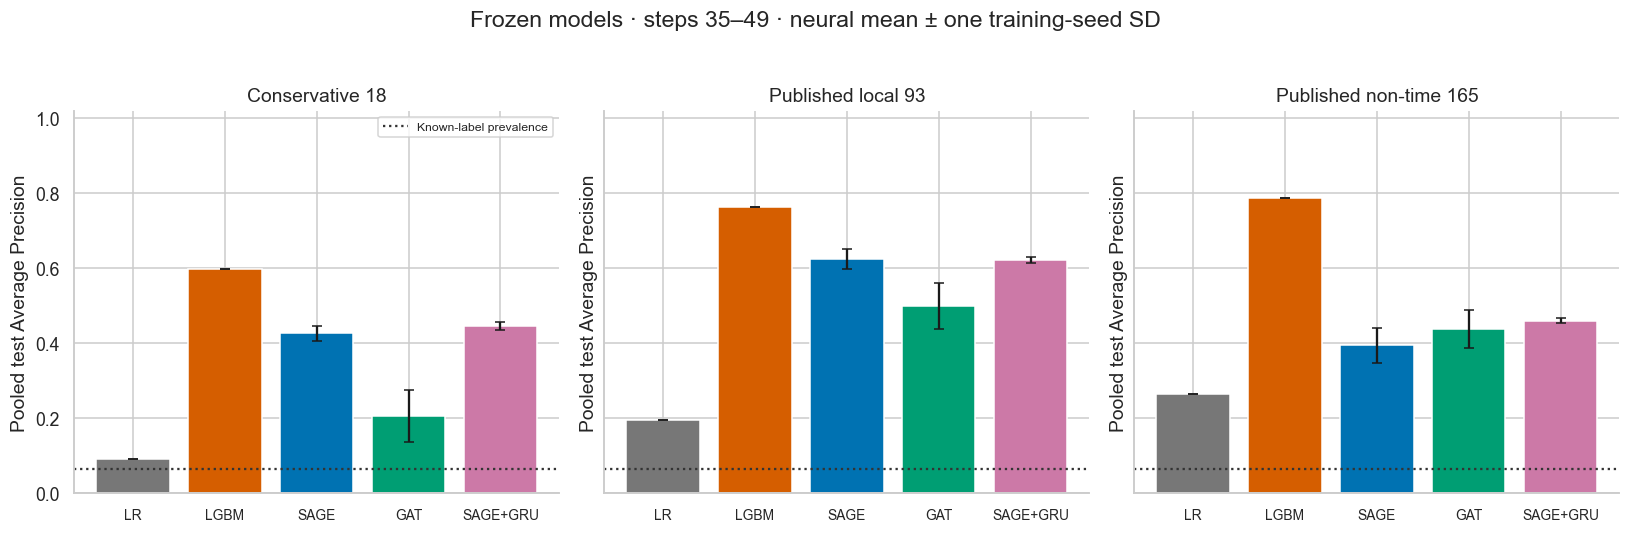

In [4]:
section_start = time.perf_counter()
metric_records, period_records = [], []
for record in model_records:
    for variant, predictions, key in [("raw", raw_predictions, "raw_thresholds"), ("platt", platt_predictions, "calibrated_thresholds")]:
        model_id = record["model_id"]
        frame = predictions.loc[predictions.model_name == model_id + "__" + variant]
        rules = bundles[model_id][key]
        metadata = {"model_id": model_id, "architecture": record["architecture"], "feature_configuration": record["feature_configuration"], "seed": record["seed"], "calibration": variant}
        metric_records.append({**metadata, **evaluate_predictions(frame, rules, REVIEW_K),
            "expected_calibration_error": expected_calibration_error(frame.true_label, frame.predicted_probability, CALIBRATION_BINS)})
        for step, part in frame.groupby("time_step"):
            result = evaluate_predictions(part, rules, REVIEW_K)
            enough_positive = int(part.true_label.sum()) >= MIN_CLASS_PER_STEP
            enough_negative = int((part.true_label == 0).sum()) >= MIN_CLASS_PER_STEP
            if not (enough_positive and enough_negative):
                result["average_precision"] = result["roc_auc"] = np.nan
            if not enough_positive:
                result["recall"] = result["recall_at_validation_target_fpr"] = np.nan
            if not enough_negative:
                result["false_positive_rate"] = result["achieved_fpr_at_validation_target"] = np.nan
            period_records.append({**metadata, "time_step": step, "ranking_metric_available": enough_positive and enough_negative,
                **result, "expected_calibration_error": expected_calibration_error(part.true_label, part.predicted_probability, CALIBRATION_BINS)})
metrics = save_table(pd.DataFrame(metric_records), "final_test_metrics.csv")
period_metrics = save_table(pd.DataFrame(period_records), "per_time_step_metrics.csv")
raw_metrics = metrics.loc[metrics.calibration == "raw"].copy()
summary = save_table(raw_metrics.groupby(["architecture", "feature_configuration"], sort=False).agg(
    ap_mean=("average_precision", "mean"), ap_seed_sd=("average_precision", "std"), seeds=("seed", "count"),
    roc_auc_mean=("roc_auc", "mean"), recall_mean=("recall", "mean"), precision_mean=("precision", "mean"),
    brier_mean=("brier_score", "mean"), fpr_mean=("false_positive_rate", "mean"),
    recall_fixed_rule_mean=("recall_at_validation_target_fpr", "mean"), review_precision_mean=("precision_at_k", "mean")).reset_index(), "model_comparison.csv")
display(summary.round(4))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.7), sharey=True)
for ax, group in zip(axes, FEATURE_GROUPS):
    view = summary.loc[summary.feature_configuration == group].set_index("architecture").loc[ARCHITECTURES]
    ax.bar(range(5), view.ap_mean, yerr=view.ap_seed_sd.fillna(0), capsize=3, color=[COLORS[a] for a in ARCHITECTURES])
    ax.axhline(known_test.target.mean(), color="#333333", ls=":", label="Known-label prevalence")
    ax.set(title=GROUP_NAMES[group], xticks=range(5), xticklabels=[SHORT[a] for a in ARCHITECTURES], ylabel="Pooled test Average Precision", ylim=(0, 1.02))
    ax.tick_params(axis="x", labelsize=9)
axes[0].legend(fontsize=8)
fig.suptitle("Frozen models · steps 35–49 · neural mean ± one training-seed SD", y=1.03)
save_figure(fig, "stage4_01_final_test_ap")
save_progress("final_test_metrics", time.perf_counter() - section_start)

**Observed pooled result.** LightGBM leads each matched feature group: AP 0.5993 / 0.7639 / 0.7866. The strongest neural mean is historical GRU for 18 features (0.4466), GraphSAGE for 93 (0.6246), and historical GRU for 165 (0.4599). Three neural seeds do not constitute three independent test populations.

The feature groups should be read separately: larger published groups contain address-history and neighborhood information with unresolved source provenance. Any observed gap is a benchmark result for this model budget and selected population; it does not establish deployment performance or universal architecture superiority.

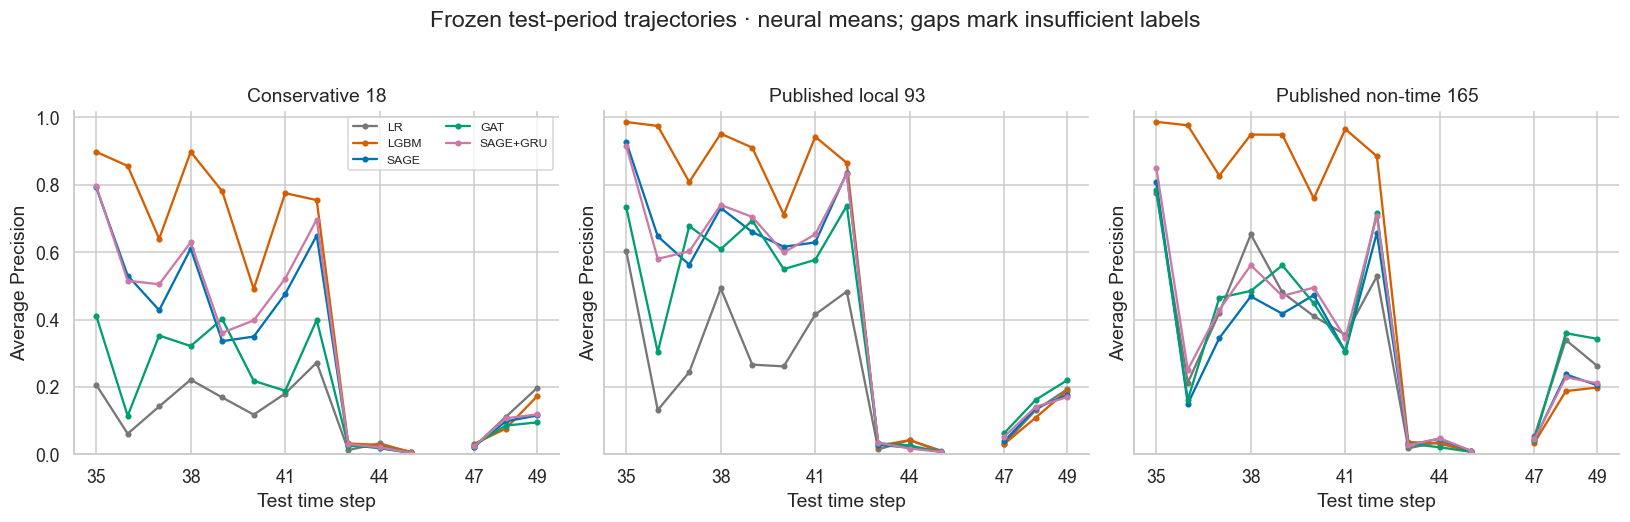

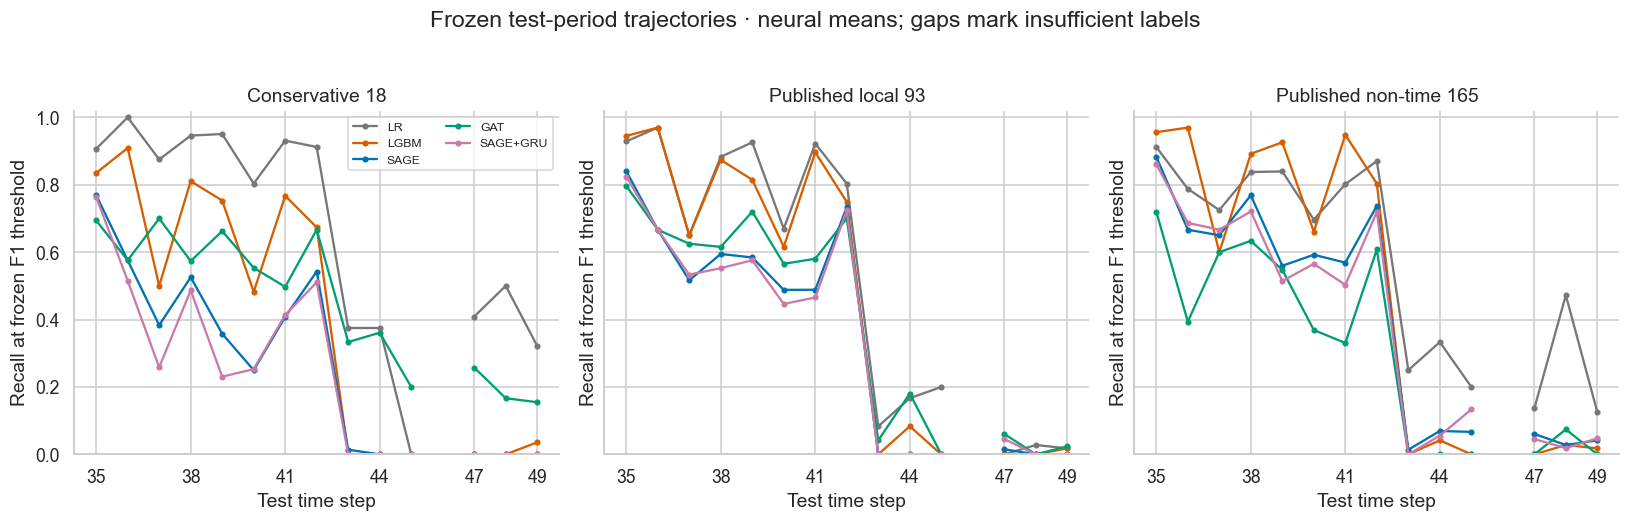

In [5]:
raw_period = period_metrics.loc[period_metrics.calibration == "raw"]
period_mean = raw_period.groupby(["architecture", "feature_configuration", "time_step"], sort=False).agg(
    average_precision=("average_precision", "mean"), recall=("recall", "mean"), brier_score=("brier_score", "mean")).reset_index()
for metric, title, filename in [("average_precision", "Average Precision", "stage4_02_ap_over_time"), ("recall", "Recall at frozen F1 threshold", "stage4_03_recall_over_time")]:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
    for ax, group in zip(axes, FEATURE_GROUPS):
        for architecture in ARCHITECTURES:
            view = period_mean.loc[(period_mean.feature_configuration == group) & (period_mean.architecture == architecture)]
            ax.plot(view.time_step, view[metric], marker="o", ms=3, color=COLORS[architecture], label=SHORT[architecture])
        ax.set(title=GROUP_NAMES[group], xlabel="Test time step", ylabel=title, ylim=(0, 1.02), xticks=[35, 38, 41, 44, 47, 49])
    axes[0].legend(fontsize=8, ncol=2)
    fig.suptitle("Frozen test-period trajectories · neural means; gaps mark insufficient labels", y=1.03)
    save_figure(fig, filename)

**Observed temporal pattern.** All model families deteriorate sharply around steps 43–47, while observed illicit prevalence also falls. AP/ROC at step 46 are unavailable under the prespecified five-per-class rule (only two illicit labels); step 45 has five positives and remains very unstable. Neural mean AP occasionally exceeds LightGBM late in the test window, but not in pooled AP. These changes do not identify concept drift or an external cause.

## 5. Natural Distribution Shift Analysis
Feature drift compares **all observed nodes in steps 1–29** with each subsequent snapshot. PSI bins come exclusively from training quantiles, with duplicate cuts collapsed and a fixed 0.5 count pseudocount. KS is reported as a distribution distance, without naive independent-observation p-values; graph observations are dependent ([SciPy assumptions](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ks_2samp.html)). Wasserstein distance is divided by training SD where that SD is nonzero.

Covariate changes do not prove concept drift. Labeled prevalence measures selected-label class proportions, not a population class prior. Changing error patterns are compatible with concept drift, label selection, graph sampling and changing class balance; this release cannot distinguish them cleanly.

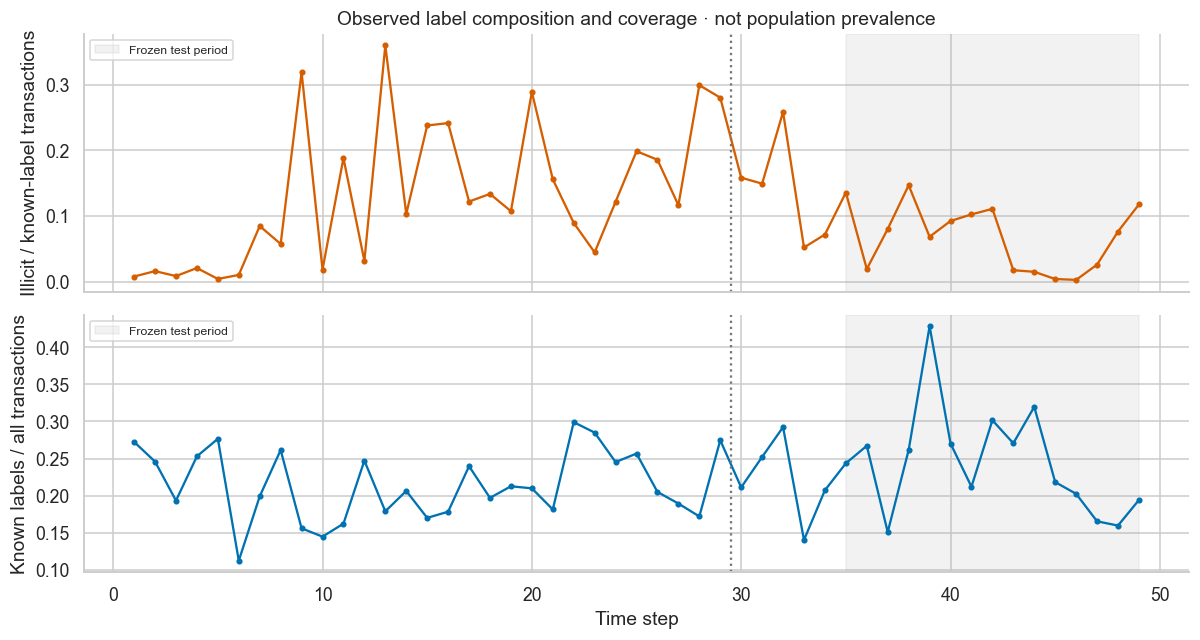

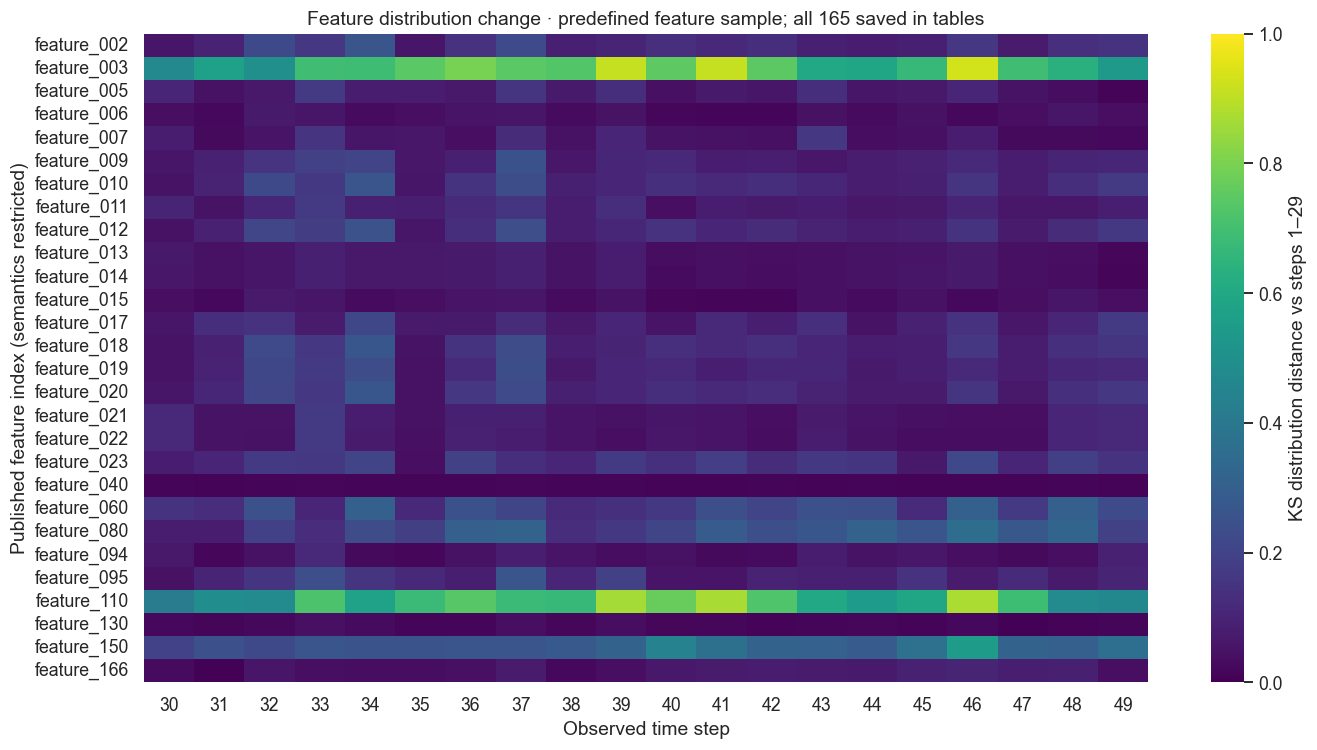

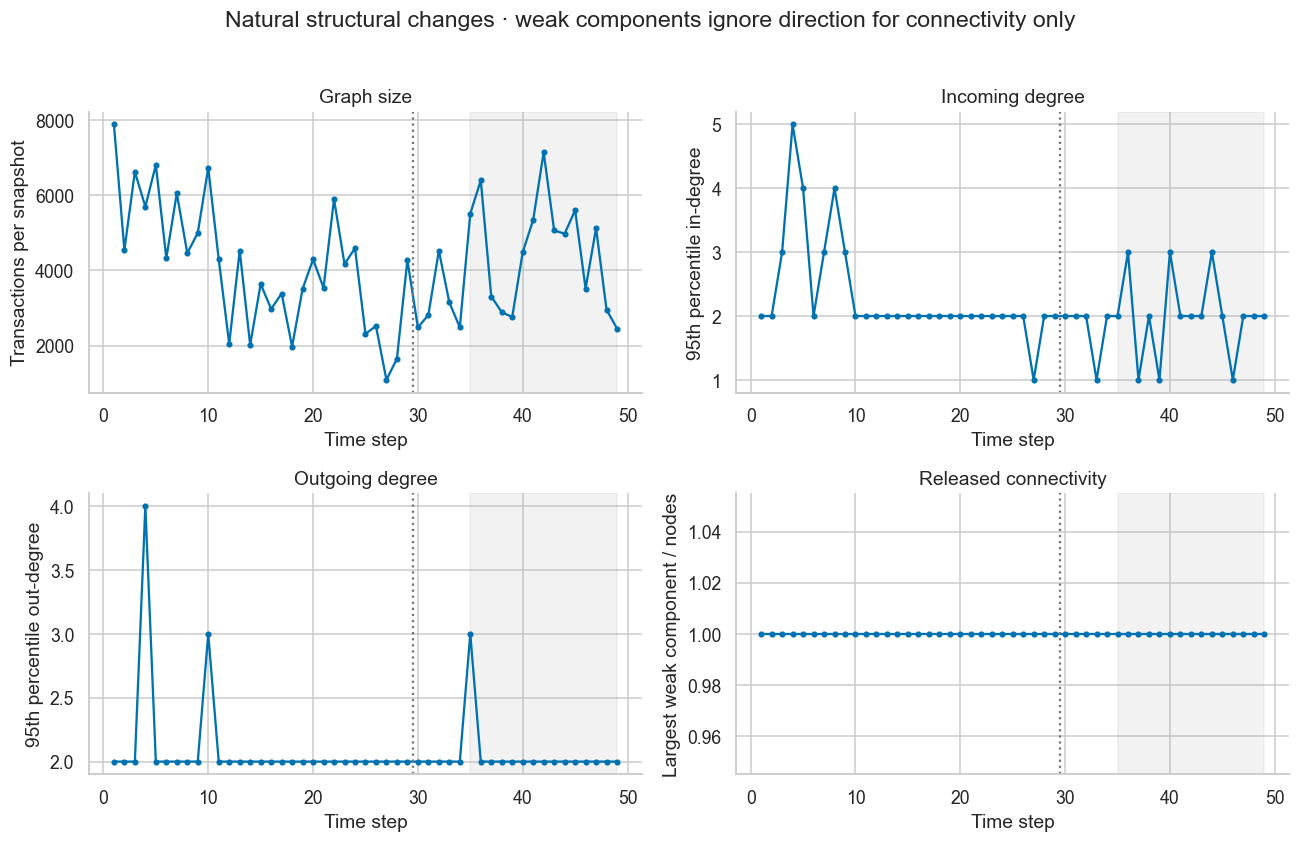

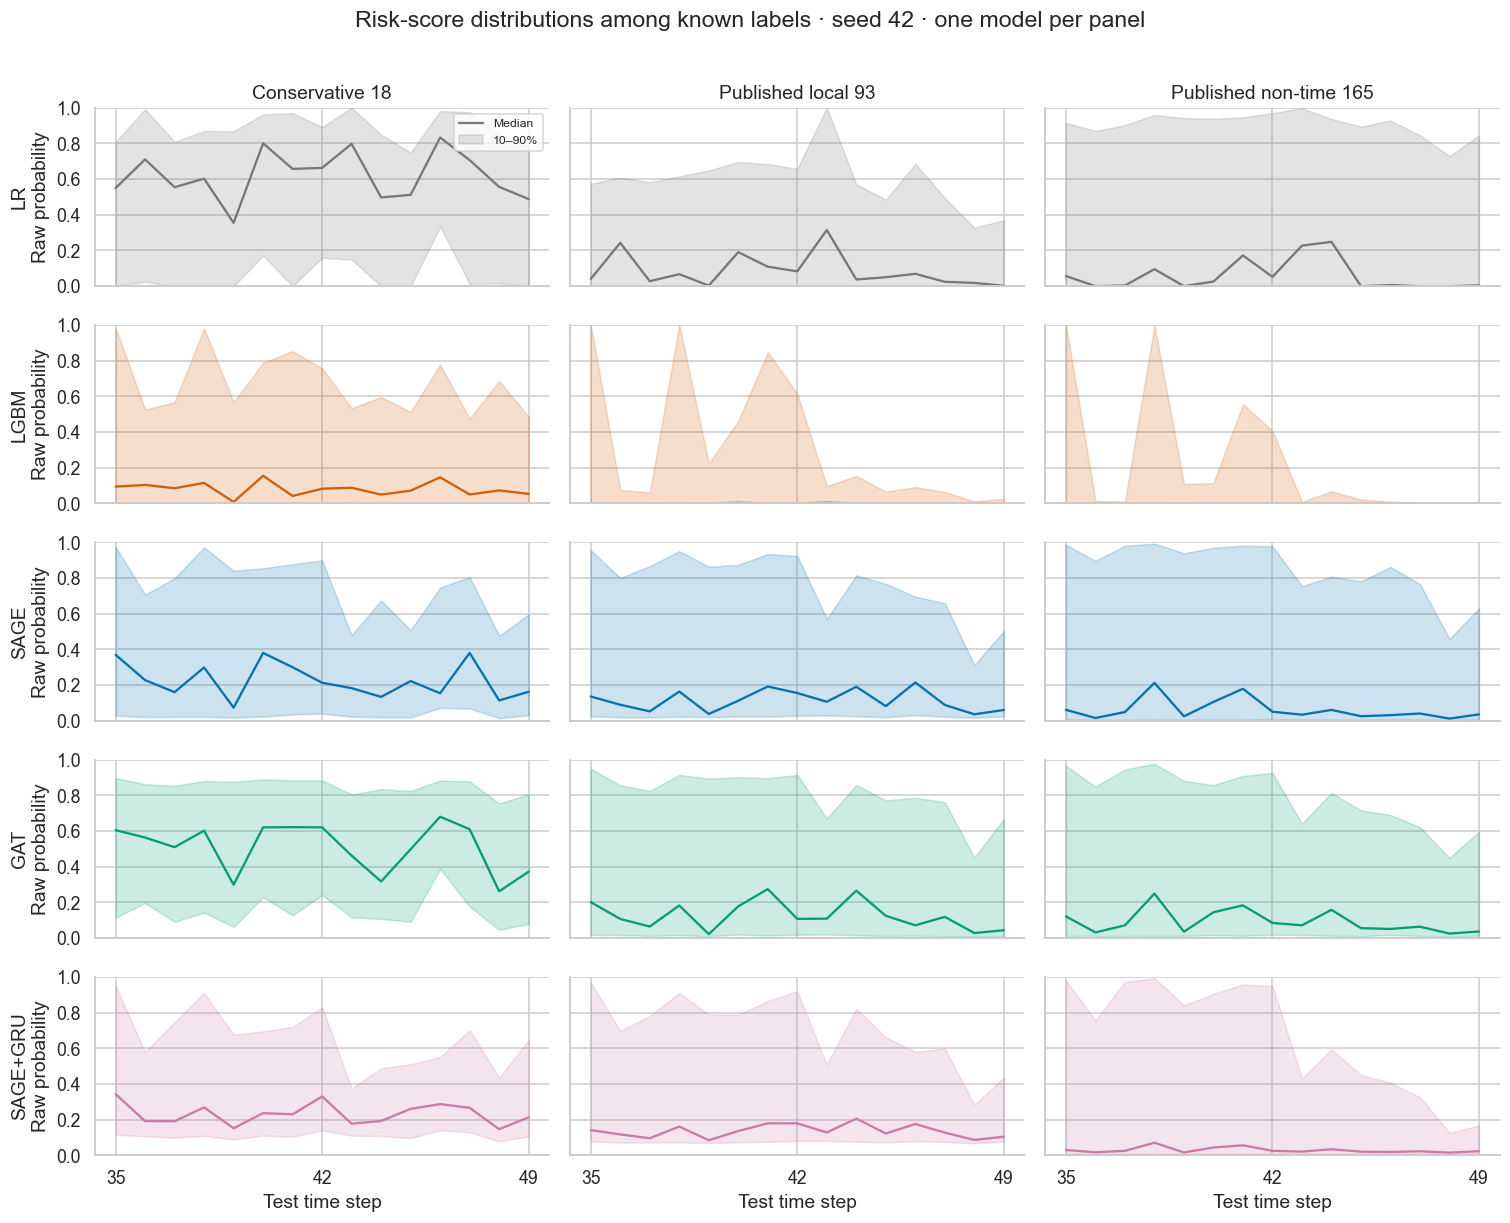

In [6]:
section_start = time.perf_counter()
if not (OFFICIAL / "feature_shift.csv").exists():
    reference = feature_nodes.loc[feature_nodes.time_step.between(1, 29)]
    drift_records = []
    for column in all_columns:
        for step in range(30, 50):
            values = feature_nodes.loc[feature_nodes.time_step == step, column]
            drift_records.append({"feature": column, "time_step": step, **distribution_shift(reference[column], values)})
    save_table(pd.DataFrame(drift_records), "feature_shift.csv")
feature_shift = cached_table("feature_shift.csv")
if not (OFFICIAL / "graph_shift.csv").exists():
    node_count = len(nodes)
    indegree = np.bincount(edges.target, minlength=node_count)
    outdegree = np.bincount(edges.source, minlength=node_count)
    graph_records = []
    component_ids = np.empty(node_count, dtype=int)
    component_sizes = np.empty(node_count, dtype=int)
    for step in range(1, 50):
        arrays = __import__("src.protocol", fromlist=["graph_at_step"]).graph_at_step(feature_nodes, edges, step, group=GROUP_KEYS["conservative18"], scope="snapshot")
        indices, adjacency = arrays["global_node_index"], arrays["edge_index"]
        sparse = coo_matrix((np.ones(adjacency.shape[1]), (adjacency[0], adjacency[1])), shape=(len(indices), len(indices))).tocsr()
        count, components = connected_components(sparse, directed=True, connection="weak")
        sizes = np.bincount(components)
        component_ids[indices] = components
        component_sizes[indices] = sizes[components]
        graph_records.append({"time_step": step, "nodes": len(indices), "edges": adjacency.shape[1], "weak_components": count,
            "largest_component_fraction": sizes.max()/len(indices), "in_degree_mean": indegree[indices].mean(),
            "in_degree_p95": np.quantile(indegree[indices], .95), "out_degree_p95": np.quantile(outdegree[indices], .95),
            "zero_in_degree_fraction": (indegree[indices] == 0).mean(), "zero_out_degree_fraction": (outdegree[indices] == 0).mean(),
            **{"in_"+k: v for k,v in distribution_shift(indegree[feature_nodes.time_step.le(29)], indegree[indices]).items()},
            **{"out_"+k: v for k,v in distribution_shift(outdegree[feature_nodes.time_step.le(29)], outdegree[indices]).items()}})
    save_table(pd.DataFrame(graph_records), "graph_shift.csv")
    np.savez_compressed(PRIVATE_DIR / "node_graph_statistics.npz", indegree=indegree, outdegree=outdegree,
                        component_id=component_ids, component_size=component_sizes)
graph_shift = cached_table("graph_shift.csv")
graph_arrays = np.load(PRIVATE_DIR / "node_graph_statistics.npz")
prevalence = snapshot_summary(nodes, edges).reset_index()
save_table(prevalence, "observed_label_shift.csv")
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(prevalence.time_step, prevalence.illicit_prevalence, color="#D55E00", marker=".")
axes[0].set(ylabel="Illicit / known-label transactions", title="Observed label composition and coverage · not population prevalence")
axes[1].plot(prevalence.time_step, prevalence.label_coverage, color="#0072B2", marker=".")
axes[1].set(xlabel="Time step", ylabel="Known labels / all transactions")
for ax in axes:
    ax.axvspan(35, 49, color="#999999", alpha=.12, label="Frozen test period")
    ax.axvline(29.5, color="#777777", ls=":")
    ax.legend(fontsize=8)
save_figure(fig, "stage4_04_prevalence_coverage")

fig, ax = plt.subplots(figsize=(13, 7))
# Fixed feature sample, including conservative, address-history and neighborhood groups.
heatmap_features = list(FEATURE_SETS["conservative18"]) + [f"feature_{i:03d}" for i in [23, 40, 60, 80, 94, 95, 110, 130, 150, 166]]
heat = feature_shift.loc[feature_shift.feature.isin(heatmap_features)].pivot(index="feature", columns="time_step", values="ks_statistic").reindex(heatmap_features)
sns.heatmap(heat, cmap="viridis", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "KS distribution distance vs steps 1–29"})
ax.set(title="Feature distribution change · predefined feature sample; all 165 saved in tables", xlabel="Observed time step", ylabel="Published feature index (semantics restricted)")
save_figure(fig, "stage4_05_feature_shift")

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, column, label in zip(axes.ravel(), ["nodes", "in_degree_p95", "out_degree_p95", "largest_component_fraction"], ["Transactions per snapshot", "95th percentile in-degree", "95th percentile out-degree", "Largest weak component / nodes"]):
    ax.plot(graph_shift.time_step, graph_shift[column], color="#0072B2", marker=".")
    ax.axvspan(35, 49, color="#999999", alpha=.12)
    ax.axvline(29.5, color="#777777", ls=":")
    ax.set(xlabel="Time step", ylabel=label)
axes[0,0].set_title("Graph size")
axes[0,1].set_title("Incoming degree")
axes[1,0].set_title("Outgoing degree")
axes[1,1].set_title("Released connectivity")
fig.suptitle("Natural structural changes · weak components ignore direction for connectivity only", y=1.02)
save_figure(fig, "stage4_06_graph_shift")

score_distribution = save_table(raw_predictions.merge(pd.DataFrame(model_records)[["model_id", "architecture", "feature_configuration"]],
    left_on=raw_predictions.model_name.str.removesuffix("__raw"), right_on="model_id")
    .groupby(["architecture", "feature_configuration", "seed", "time_step"]).predicted_probability.agg(
        score_q10=lambda x: x.quantile(.1), score_median="median", score_q90=lambda x: x.quantile(.9)).reset_index(), "risk_score_distribution.csv")
fig, axes = plt.subplots(5, 3, figsize=(14, 11), sharex=True, sharey=True)
for row, architecture in enumerate(ARCHITECTURES):
    for column, group in enumerate(FEATURE_GROUPS):
        ax = axes[row, column]
        view = score_distribution.loc[(score_distribution.feature_configuration == group) & (score_distribution.architecture == architecture) & (score_distribution.seed == PRIMARY_SEED)]
        ax.plot(view.time_step, view.score_median, color=COLORS[architecture], label="Median")
        ax.fill_between(view.time_step, view.score_q10, view.score_q90, color=COLORS[architecture], alpha=.20, label="10–90%")
        ax.set(ylim=(0,1), xticks=[35, 42, 49])
        if row == 0:
            ax.set_title(GROUP_NAMES[group])
        if column == 0:
            ax.set_ylabel(SHORT[architecture] + "\nRaw probability")
        if row == 4:
            ax.set_xlabel("Test time step")
axes[0,0].legend(fontsize=8, loc="upper right")
fig.suptitle("Risk-score distributions among known labels · seed 42 · one model per panel", y=1.01)
save_figure(fig, "stage4_07_risk_scores")
save_progress("natural_distribution_shift", time.perf_counter() - section_start)

**Observed shift.** The median KS distance across all 165 features varies from roughly 0.063 to 0.124 over the test snapshots. The released graph remains one weak component per snapshot, while size and degree tails vary. Feature drift does not show a uniquely dominant break at the performance collapse; label selection, changing prevalence and unresolved source semantics remain plausible explanations.

The graph connectivity curve can be flat even when degree tails and graph sizes change: a single weak component does not imply constant neighborhoods. Risk-score shifts may reflect changed covariates, calibration or model behavior; they cannot identify an external event as the cause.

## 6. Controlled Robustness Experiments
All models retain their weights, preprocessing, calibrators and thresholds. Noise is $x'_j=x_j+\alpha s_{j,train}\epsilon$, with $\epsilon\sim N(0,1)$. Masking replaces independent entries with the known-training mean **before** preprocessing. Common random fields align models and feature subsets; masking and edge-removal sets are nested across severity levels. We do not clip noisy values or reinterpret 10% noise as 10% missingness.

Edge removal deletes $\lfloor\alpha E_t\rfloor$ directed edges. Partial rewiring replaces the same number with unique directed non-self edges absent from the original graph. Total edge count is preserved for rewiring; degrees are not. Both experiments keep snapshot boundaries. Published precomputed features are **unchanged** under edge changes, creating an adjacency/feature inconsistency, especially for the 165-feature models.

For the GRU, steps 1–34 remain clean. Corruption applies to **all observed nodes in 35–49**, and each corrupted test summary updates later historical context after its prediction. This is a persistent-corruption scenario, not a current-snapshot-only intervention. Two perturbation seeds are crossed with all three neural training seeds; the two variability sources are saved separately.

Saved perturbation scenario: noise__0.1__seed2026


Saved perturbation scenario: noise__0.1__seed2027


Saved perturbation scenario: noise__0.2__seed2026


Saved perturbation scenario: noise__0.2__seed2027


Saved perturbation scenario: noise__0.3__seed2026


Saved perturbation scenario: noise__0.3__seed2027


... (14 outputs left out)

Saved perturbation scenario: rewire__0.2__seed2026


Saved perturbation scenario: rewire__0.2__seed2027


Saved perturbation scenario: rewire__0.3__seed2026


Saved perturbation scenario: rewire__0.3__seed2027


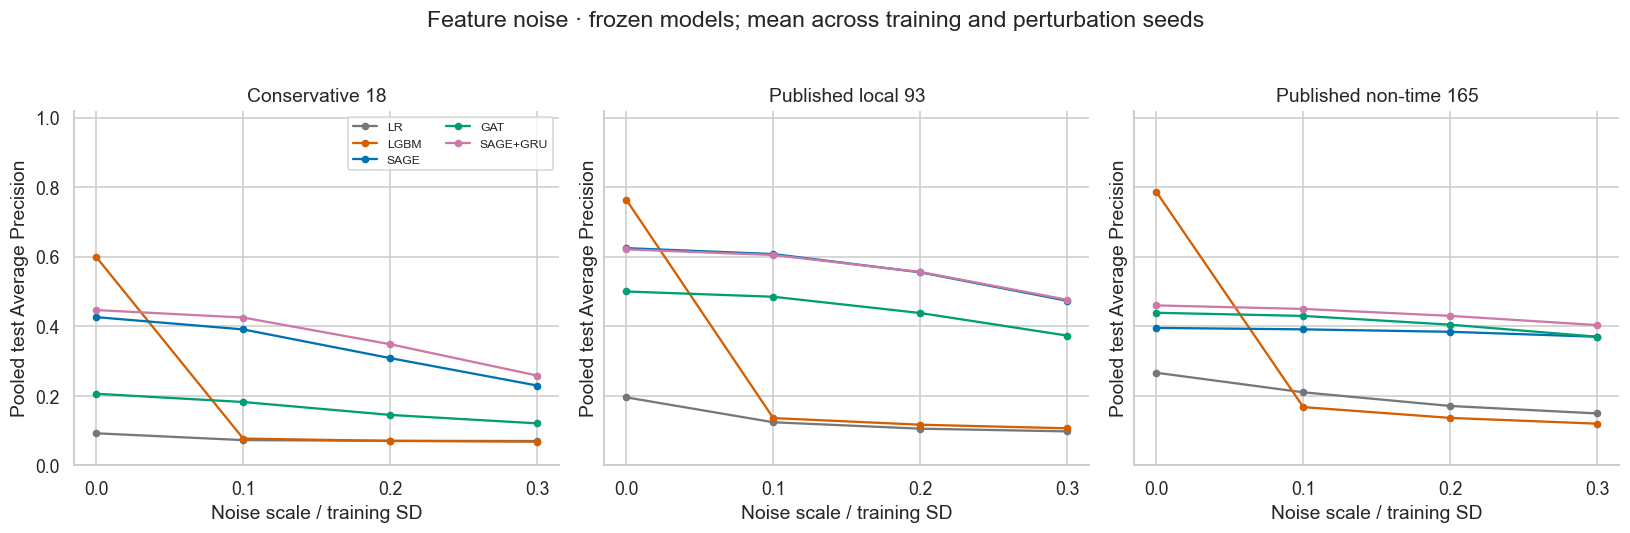

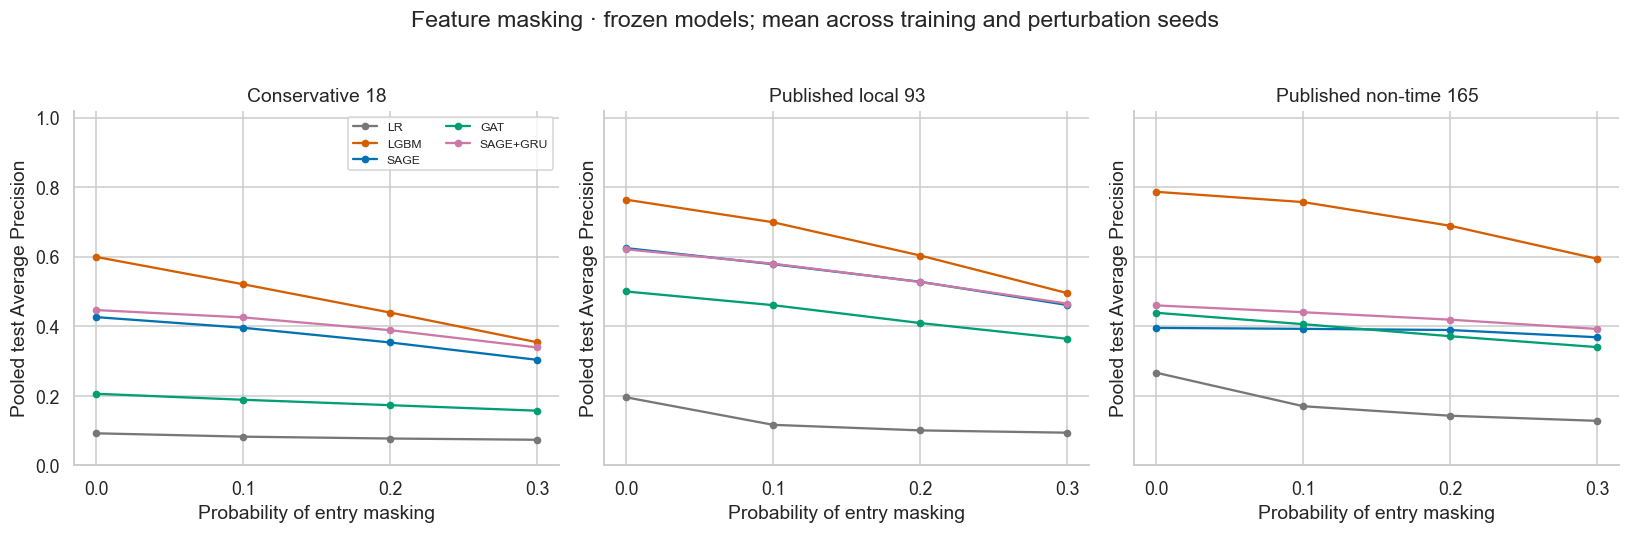

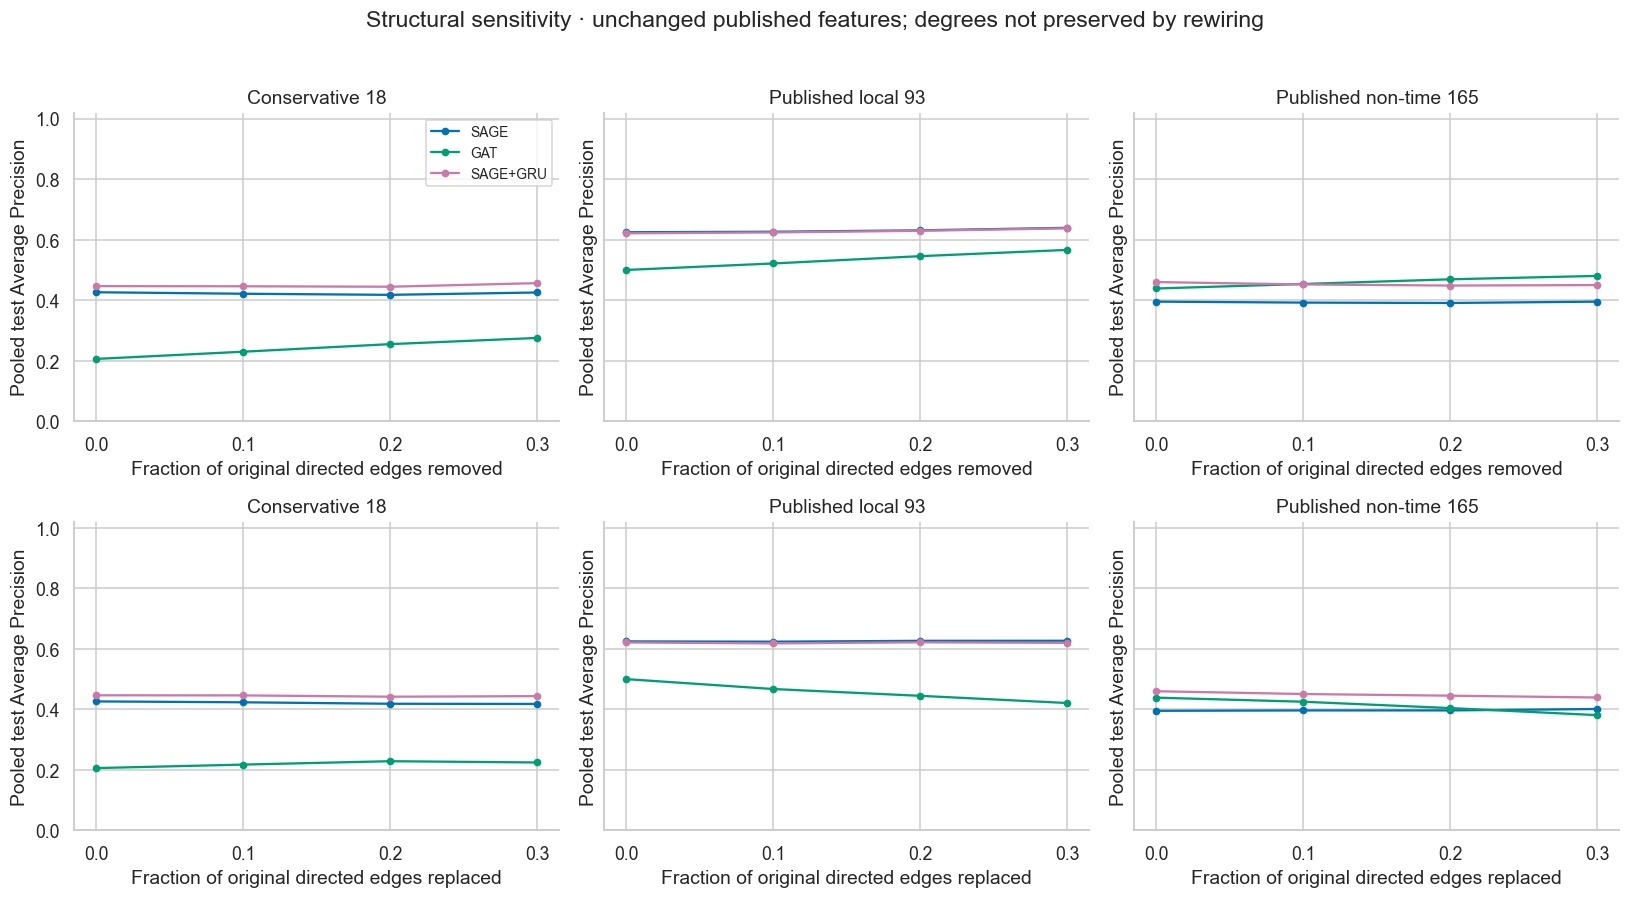

In [7]:
section_start = time.perf_counter()
robust_path = OFFICIAL / "robustness_results.csv"
if not robust_path.exists():
    if not ALLOW_NEW_INFERENCE:
        raise RuntimeError("Missing robustness aggregate: use scripts/validate_cache.py --recover-tables for complete committed caches; no automatic new inference.")
    if QUICK_RUN:
        raise RuntimeError("QUICK_RUN cannot run uncached official perturbations")
    verify_frozen(ROOT, PROTOCOL_PATH, protocol_hash)
    if not original_graphs:
        original_graphs = {group: stage4_snapshots(feature_nodes, edges, scalers[group], GROUP_KEYS[group], protocol) for group in FEATURE_GROUPS}
    all_test_rows = pd.concat([nodes.iloc[original_graphs[FEATURE_GROUPS[0]][t].node_index.numpy()] for t in range(35,50)])
    known_mask = all_test_rows.target.notna().to_numpy()
    rows = all_test_rows.loc[known_mask]
    np.testing.assert_array_equal(rows.tx_id.astype(str), known_test.tx_id.astype(str))
    for record in model_records:
        if record["kind"] == "graph" and record["model_id"] not in contexts:
            group, device = record["feature_configuration"], devices[record["model_id"]]
            if (group, device) not in device_graphs:
                device_graphs[(group, device)] = {t: g.clone().to(device) for t,g in original_graphs[group].items()}
            contexts[record["model_id"]] = context_before_test(models[record["model_id"]], device_graphs[(group, device)])
    scenario_folder = PRIVATE_DIR / "perturbations"
    scenario_folder.mkdir(exist_ok=True)
    aggregate_records, edge_change_records = [], []
    for kind in ["noise", "mask", "remove", "rewire"]:
        for severity in SEVERITIES:
            for perturb_seed in PERTURBATION_SEEDS:
                scenario = f"{kind}__{severity:.1f}__seed{perturb_seed}"
                scenario_table = PRIVATE_DIR / f"metrics__{scenario}.csv"
                if scenario_table.exists() or (scenario_folder / f"{scenario}.npz").exists():
                    saved_metrics, saved_edges = read_committed_scenario(PRIVATE_DIR, scenario, protocol_hash)
                    validate_scenario_metrics(saved_metrics, protocol, kind, severity, perturb_seed)
                    validate_edge_audit(saved_edges, protocol, graph_shift, kind, severity, perturb_seed)
                    aggregate_records.extend(saved_metrics.to_dict("records"))
                    edge_change_records.extend(saved_edges.to_dict("records"))
                    continue
                scenario_records, probability_arrays = [], {}
                for group in FEATURE_GROUPS:
                    columns = FEATURE_SETS[group]
                    changed_graphs, changes = modified_snapshots(original_graphs[group], feature_nodes, columns, scalers[group],
                        train_means[columns].to_numpy(), train_sds[columns].to_numpy(), kind, severity, perturb_seed, list(range(35,50)))
                    edge_change_records.extend({"feature_configuration": group, "kind": kind, "severity": severity, "perturbation_seed": perturb_seed, **c} for c in changes)
                    group_graphs = {}
                    for record in [r for r in model_records if r["feature_configuration"] == group]:
                        if kind in ["remove", "rewire"] and record["kind"] != "graph":
                            continue
                        model_id = record["model_id"]
                        if record["kind"] == "graph":
                            device = devices[model_id]
                            if device not in group_graphs:
                                group_graphs[device] = {t: g.clone().to(device) for t,g in changed_graphs.items()}
                            scores = infer_test_graphs(models[model_id], group_graphs[device], contexts[model_id])
                            probability = expit(scores[known_mask])
                        else:
                            indices = [int(name.split("_")[1]) - 2 for name in columns]
                            parts = []
                            for step in range(35, 50):
                                all_rows = feature_nodes.loc[feature_nodes.time_step == step]
                                values = perturb_features(all_rows[columns].to_numpy(), train_means[columns].to_numpy(), train_sds[columns].to_numpy(), indices, kind, severity, perturb_seed, step)
                                visible_known = nodes.loc[all_rows.index, "target"].notna().to_numpy()
                                parts.append(pd.DataFrame(values[visible_known], columns=columns))
                            features = pd.concat(parts, ignore_index=True)
                            with threadpool_limits(limits=CPU_THREADS):
                                probability = expit(decision_scores(models[model_id], features))
                        frame = test_prediction_frame(rows, probability, model_id, record["seed"])
                        rules = bundles[model_id]["raw_thresholds"]
                        observed = binary_metrics(frame.true_label, frame.predicted_probability, rules["f1_threshold"])
                        unperturbed = raw_metrics.loc[raw_metrics.model_id == model_id].iloc[0]
                        scenario_records.append({"model_id": model_id, "architecture": record["architecture"],
                            "feature_configuration": group, "training_seed": record["seed"], "perturbation_seed": perturb_seed,
                            "perturbation": kind, "severity": severity, "average_precision": observed["average_precision"],
                            "precision": observed["precision"], "recall": observed["recall"],
                            "delta_ap": observed["average_precision"] - unperturbed.average_precision,
                            "delta_precision": observed["precision"] - unperturbed.precision,
                            "delta_recall": observed["recall"] - unperturbed.recall,
                            "n_labeled": len(rows), "probability_cache": f"perturbations/{scenario}.npz"})
                        probability_arrays[model_id] = probability
                np.savez_compressed(scenario_folder / f"{scenario}.npz", **probability_arrays)
                atomic_csv(pd.DataFrame(scenario_records), scenario_table)
                scenario_edges = pd.DataFrame(edge_change_records)
                scenario_edges = scenario_edges.loc[scenario_edges.kind.eq(kind) & np.isclose(scenario_edges.severity, severity) & scenario_edges.perturbation_seed.eq(perturb_seed)]
                atomic_csv(scenario_edges, PRIVATE_DIR / f"edge_audit__{scenario}.csv")
                commit_scenario(PRIVATE_DIR, scenario, protocol_hash)
                aggregate_records.extend(scenario_records)
                print("Saved perturbation scenario:", scenario)
    atomic_csv(pd.DataFrame(aggregate_records), OFFICIAL / "robustness_results.csv")
    atomic_csv(pd.DataFrame(edge_change_records), OFFICIAL / "perturbation_edge_counts.csv")
    audit_stage4_cache(ROOT, adopt_legacy=True, base=BASE, private=PRIVATE_DIR)
robustness = cached_table("robustness_results.csv")
robust_mean = save_table(robustness.groupby(["architecture", "feature_configuration", "perturbation", "severity"]).agg(
    ap_mean=("average_precision", "mean"), ap_crossed_sd=("average_precision", "std"),
    delta_ap_mean=("delta_ap", "mean"), recall_mean=("recall", "mean"), precision_mean=("precision", "mean")).reset_index(), "robustness_summary.csv")
within_training_seed = robustness.groupby(["architecture", "feature_configuration", "perturbation", "severity", "training_seed"]).agg(
    ap_mean_across_perturbations=("average_precision", "mean"), ap_perturbation_sd=("average_precision", "std")).reset_index()
save_table(within_training_seed, "robustness_separate_variability.csv")
for kind, title, filename in [("noise", "Feature noise", "stage4_08_feature_noise"), ("mask", "Feature masking", "stage4_09_feature_masking")]:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.7), sharey=True)
    for ax, group in zip(axes, FEATURE_GROUPS):
        for architecture in ARCHITECTURES:
            view = robust_mean.loc[(robust_mean.architecture == architecture) & (robust_mean.feature_configuration == group) & (robust_mean.perturbation == kind)].sort_values("severity")
            baseline = summary.loc[(summary.architecture == architecture) & (summary.feature_configuration == group), "ap_mean"].item()
            ax.plot([0] + view.severity.tolist(), [baseline] + view.ap_mean.tolist(), marker="o", ms=4, color=COLORS[architecture], label=SHORT[architecture])
        ax.set(title=GROUP_NAMES[group], xlabel="Noise scale / training SD" if kind == "noise" else "Probability of entry masking", ylabel="Pooled test Average Precision", ylim=(0,1.02), xticks=[0,.1,.2,.3])
    axes[0].legend(fontsize=8, ncol=2)
    fig.suptitle(f"{title} · frozen models; mean across training and perturbation seeds", y=1.03)
    save_figure(fig, filename)
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for row, kind in enumerate(["remove", "rewire"]):
    for ax, group in zip(axes[row], FEATURE_GROUPS):
        for architecture in ["graphsage", "gat", "sage_gru"]:
            view = robust_mean.loc[(robust_mean.architecture == architecture) & (robust_mean.feature_configuration == group) & (robust_mean.perturbation == kind)].sort_values("severity")
            baseline = summary.loc[(summary.architecture == architecture) & (summary.feature_configuration == group), "ap_mean"].item()
            ax.plot([0] + view.severity.tolist(), [baseline] + view.ap_mean.tolist(), color=COLORS[architecture], marker="o", ms=4, label=SHORT[architecture])
        ax.set(title=GROUP_NAMES[group], xlabel="Fraction of original directed edges " + ("removed" if kind == "remove" else "replaced"), ylabel="Pooled test Average Precision", ylim=(0,1.02), xticks=[0,.1,.2,.3])
axes[0,0].legend(fontsize=9)
fig.suptitle("Structural sensitivity · unchanged published features; degrees not preserved by rewiring", y=1.02)
save_figure(fig, "stage4_10_edge_robustness")
save_progress("controlled_robustness", time.perf_counter() - section_start)

**Observed robustness.** At noise scale 0.30 training SD, historical-GRU AP is 0.2582 / 0.4761 / 0.4033, versus LightGBM 0.0681 / 0.1065 / 0.1199. This is sensitivity to the specified unbounded Gaussian stress, not evidence of realistic financial resilience. Under 30% entry masking, LightGBM remains ahead in all three groups. Thirty-percent edge removal improves mean GAT AP by about 0.069 / 0.066 / 0.042; message passing is not consistently helpful under this frozen setup.

Each curve uses the same labeled candidates and saved threshold. Absolute AP and change from each model’s own unperturbed AP are both saved: a small degradation from a weak starting point does not imply a better detector. Two perturbation draws provide a limited sensitivity check, not broad corruption-distribution uncertainty.

## 7. Statistical Comparison and Confidence Intervals
The 15 observed test snapshots are resampled in length-three circular blocks, with all models sharing the same draw. Within each replicate, we recompute **pooled AP**, then average individual neural-seed APs. We do not average probabilities into a new ensemble or treat training seeds as extra temporal observations. Paired differences compare matching feature groups and transaction identities.

The implementation uses multiplicity weights, equivalent to physically repeating the selected snapshot rows; this equivalence is tested. The procedure follows the [circular block-bootstrap convention](https://bashtage.github.io/arch/bootstrap/generated/arch.bootstrap.CircularBlockBootstrap.html), implemented with NumPy to avoid another dependency. The wrap from 49 to 35 is a computational boundary convention. Only 15 periods and five sampled blocks per replicate make coverage and tail quantiles uncertain, especially under nonstationarity.

,feature_configuration,first_architecture,second_architecture,observed_ap_difference,ci_low,ci_high,valid_replications
0,conservative18,lightgbm,graphsage,0.1731,0.0785,0.2501,1000
1,conservative18,lightgbm,gat,0.3934,0.1950,0.4695,1000
2,conservative18,lightgbm,sage_gru,0.1528,0.0535,0.2390,1000
3,conservative18,sage_gru,graphsage,0.0203,-0.0072,0.0400,1000
4,local93,lightgbm,graphsage,0.1393,0.0647,0.2181,1000
5,local93,lightgbm,gat,0.2640,0.1838,0.3417,1000
6,local93,lightgbm,sage_gru,0.1428,0.0700,0.2215,1000
7,local93,sage_gru,graphsage,-0.0035,-0.0110,0.0067,1000
8,published165,lightgbm,graphsage,0.3913,0.2354,0.4900,1000
9,published165,lightgbm,gat,0.3478,0.1934,0.4424,1000


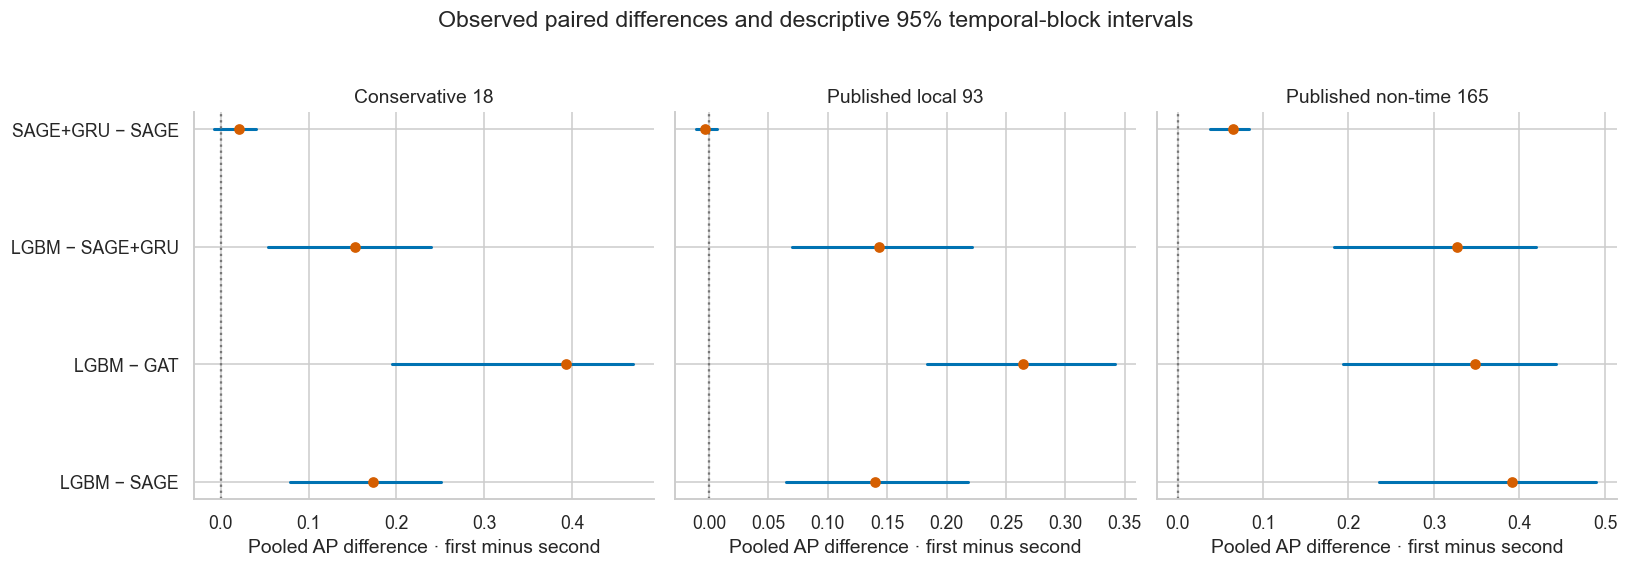

In [8]:
section_start = time.perf_counter()
if not (OFFICIAL / "paired_bootstrap_intervals.csv").exists():
    counts = circular_block_counts(15, BOOTSTRAP_BLOCK_LENGTH, BOOTSTRAP_REPETITIONS, BOOTSTRAP_SEED)
    np.savez_compressed(PRIVATE_DIR / "bootstrap_snapshot_counts.npz", counts=counts)
    canonical = raw_predictions.loc[raw_predictions.model_name == model_records[0]["model_id"] + "__raw"].sort_values("transaction_id").reset_index(drop=True)
    bootstrap_values = {}
    for record in model_records:
        frame = raw_predictions.loc[raw_predictions.model_name == record["model_id"] + "__raw"]
        frame, _ = aligned_pair(frame, canonical)
        bootstrap_values[record["model_id"]] = bootstrap_ap(frame.true_label.to_numpy(), frame.predicted_probability.to_numpy(), frame.time_step.to_numpy() - 35, counts)
    np.savez_compressed(PRIVATE_DIR / "bootstrap_model_ap.npz", **bootstrap_values)
    comparison_records, replicate_records = [], []
    for group in FEATURE_GROUPS:
        for first, second in protocol["bootstrap"]["pairs"]:
            first_ids = [r["model_id"] for r in model_records if r["architecture"] == first and r["feature_configuration"] == group]
            second_ids = [r["model_id"] for r in model_records if r["architecture"] == second and r["feature_configuration"] == group]
            first_values = np.mean([bootstrap_values[name] for name in first_ids], axis=0)
            second_values = np.mean([bootstrap_values[name] for name in second_ids], axis=0)
            difference = first_values - second_values
            finite = difference[np.isfinite(difference)]
            observed = summary.loc[(summary.architecture == first) & (summary.feature_configuration == group), "ap_mean"].item() - summary.loc[(summary.architecture == second) & (summary.feature_configuration == group), "ap_mean"].item()
            low, high = np.percentile(finite, [2.5,97.5])
            comparison_records.append({"feature_configuration": group, "first_architecture": first, "second_architecture": second,
                "observed_ap_difference": observed, "relative_difference_to_second": observed / summary.loc[(summary.architecture == second) & (summary.feature_configuration == group), "ap_mean"].item(),
                "ci_low": low, "ci_high": high, "snapshots": 15, "block_length": BOOTSTRAP_BLOCK_LENGTH,
                "blocks_per_draw": 5, "replications": BOOTSTRAP_REPETITIONS, "valid_replications": len(finite), "bootstrap_seed": BOOTSTRAP_SEED,
                "interval_type": "pointwise percentile; not multiplicity-adjusted"})
            replicate_records.extend({"feature_configuration": group, "first_architecture": first, "second_architecture": second, "replicate": i, "ap_difference": value} for i,value in enumerate(difference))
    save_table(pd.DataFrame(comparison_records), "paired_bootstrap_intervals.csv")
    save_table(pd.DataFrame(replicate_records), "bootstrap_difference_replicates.csv")
intervals = cached_table("paired_bootstrap_intervals.csv")
display(intervals[["feature_configuration", "first_architecture", "second_architecture", "observed_ap_difference", "ci_low", "ci_high", "valid_replications"]].round(4))
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, group in zip(axes, FEATURE_GROUPS):
    view = intervals.loc[intervals.feature_configuration == group].reset_index(drop=True)
    for position, row in view.iterrows():
        ax.plot([row.ci_low, row.ci_high], [position, position], color="#0072B2", linewidth=2)
        ax.scatter(row.observed_ap_difference, position, color="#D55E00", zorder=3)
    ax.axvline(0, color="#777777", ls=":")
    ax.set(title=GROUP_NAMES[group], xlabel="Pooled AP difference · first minus second", yticks=range(4), yticklabels=[f"{SHORT[r.first_architecture]} − {SHORT[r.second_architecture]}" for r in view.itertuples()])
fig.suptitle("Observed paired differences and descriptive 95% temporal-block intervals", y=1.03)
save_figure(fig, "stage4_11_paired_uncertainty")
save_progress("temporal_block_bootstrap", time.perf_counter() - section_start)

**Observed paired differences.** All nine LightGBM-minus-GNN descriptive intervals lie above zero. Historical-GRU minus static-SAGE AP is +0.0203 (18), −0.0035 (93), and +0.0647 (165); only the 165-feature interval excludes zero under this resampling scheme. The 18/93 intervals include zero. These are pointwise, assumption-dependent comparisons, not definitive significance claims or isolated evidence for history.

An interval excluding zero describes this resampling scheme’s stability conditional on the observed release, models and labels. It is not definitive evidence of generalization significance: dependence may extend beyond three snapshots, there are only 15 observed periods, labels are selective, and 12 pointwise comparisons are displayed. Training-seed SD quantifies a different source of variation.

## 8. Model Convergence Analysis
We inspect saved development histories, without retraining capped fits. One Stage 3 epoch was **one full-batch optimizer update**, with a 60-epoch cap. A rising selection-AP tail indicates that the chosen budget may matter; a capped fit alone does not prove underfitting. No test outcome is used to extend a budget or change an architecture.

Capped fits: 19 / 44
Capped selected main models: 9 / 27


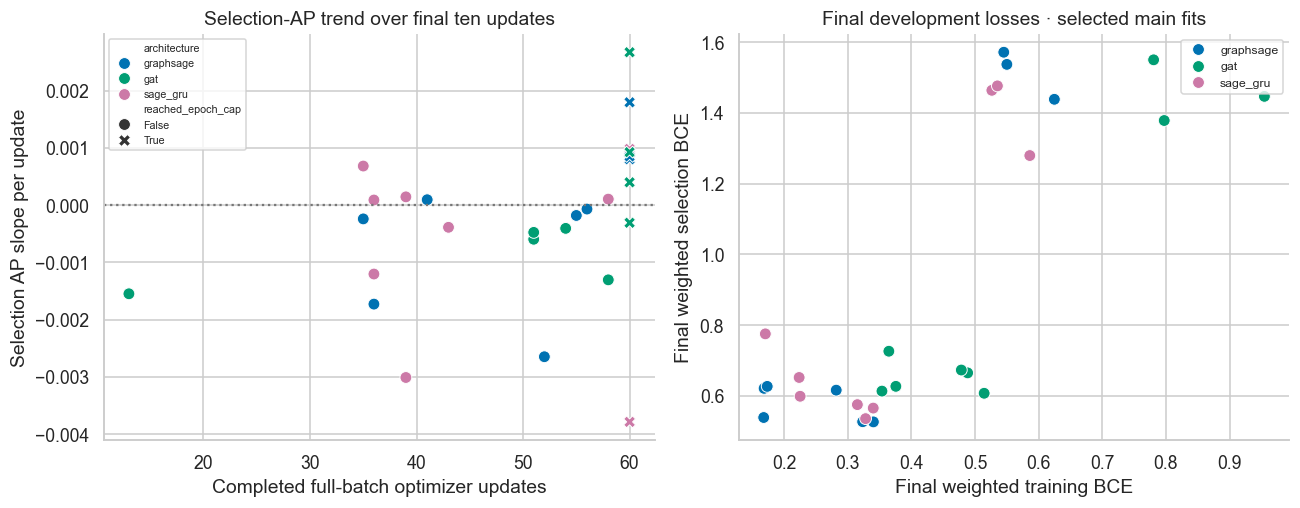

In [9]:
section_start = time.perf_counter()
fit_progress = pd.read_csv(ROOT / "results/stage3/full_run/fit_progress.csv")
selected_ids = {r["run_id"] for r in model_records if r["kind"] == "graph"}
convergence_records = []
for run in fit_progress.to_dict("records"):
    history = pd.read_csv(ROOT / "results/stage3/full_run/histories" / f"{run['run_id']}.csv")
    tail = history.tail(min(10, len(history)))
    slope = np.polyfit(tail.epoch, tail.selection_ap, 1)[0] if len(tail) > 1 else np.nan
    convergence_records.append({"run_id": run["run_id"], "architecture": run["architecture"], "feature_configuration": run["feature_configuration"],
        "seed": run["seed"], "epochs_run": run["epochs_run"], "best_epoch": run["best_epoch"],
        "reached_epoch_cap": run["epochs_run"] == neural_config["max_epochs"], "selected_main": run["run_id"] in selected_ids,
        "final_training_loss": history.training_loss.iloc[-1], "final_selection_loss": history.selection_loss.iloc[-1],
        "final_selection_ap": history.selection_ap.iloc[-1], "tail_selection_ap_slope_per_epoch": slope,
        "selection_ap_last_minus_first_tail": tail.selection_ap.iloc[-1] - tail.selection_ap.iloc[0]})
convergence = save_table(pd.DataFrame(convergence_records), "convergence_summary.csv")
print("Capped fits:", int(convergence.reached_epoch_cap.sum()), "/", len(convergence))
print("Capped selected main models:", int((convergence.reached_epoch_cap & convergence.selected_main).sum()), "/", int(convergence.selected_main.sum()))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
view = convergence.loc[convergence.selected_main]
sns.scatterplot(data=view, x="epochs_run", y="tail_selection_ap_slope_per_epoch", hue="architecture", style="reached_epoch_cap", palette={a: COLORS[a] for a in ["graphsage","gat","sage_gru"]}, ax=axes[0], s=60)
axes[0].axhline(0, color="#777777", ls=":")
axes[0].set(title="Selection-AP trend over final ten updates", xlabel="Completed full-batch optimizer updates", ylabel="Selection AP slope per update")
sns.scatterplot(data=view, x="final_training_loss", y="final_selection_loss", hue="architecture", palette={a: COLORS[a] for a in ["graphsage","gat","sage_gru"]}, ax=axes[1], s=60)
axes[1].set(title="Final development losses · selected main fits", xlabel="Final weighted training BCE", ylabel="Final weighted selection BCE")
axes[1].legend(fontsize=8)
axes[0].legend(fontsize=7)
save_figure(fig, "stage4_12_convergence")
save_progress("saved_history_convergence", time.perf_counter() - section_start)

The existing temporal head is linear: $\ell_{it}=w_z^T z_{it}+w_h^T h_{t-1}+b$. For fixed weights, $w_h^T h_{t-1}$ is common to every transaction in snapshot $t$. It can alter probability levels, thresholds and pooled cross-snapshot rankings, but cannot directly change rankings **within** a snapshot. Differences between separately trained static and temporal models also reflect different encoder learning. We retain this architecture and do not infer a causal temporal benefit from its AP.

## 9. Error Analysis
Aggregate errors use the saved raw F1 rules and primary seed 42 for readable case comparisons. Predefined degree bins are 0, 1, 2–4, 5–9 and 10+. Confidence bins use fixed raw probability boundaries, not test quantiles. Component membership is descriptive; no IDs or per-transaction records are exported publicly. These exploratory error summaries do not choose a new detector.

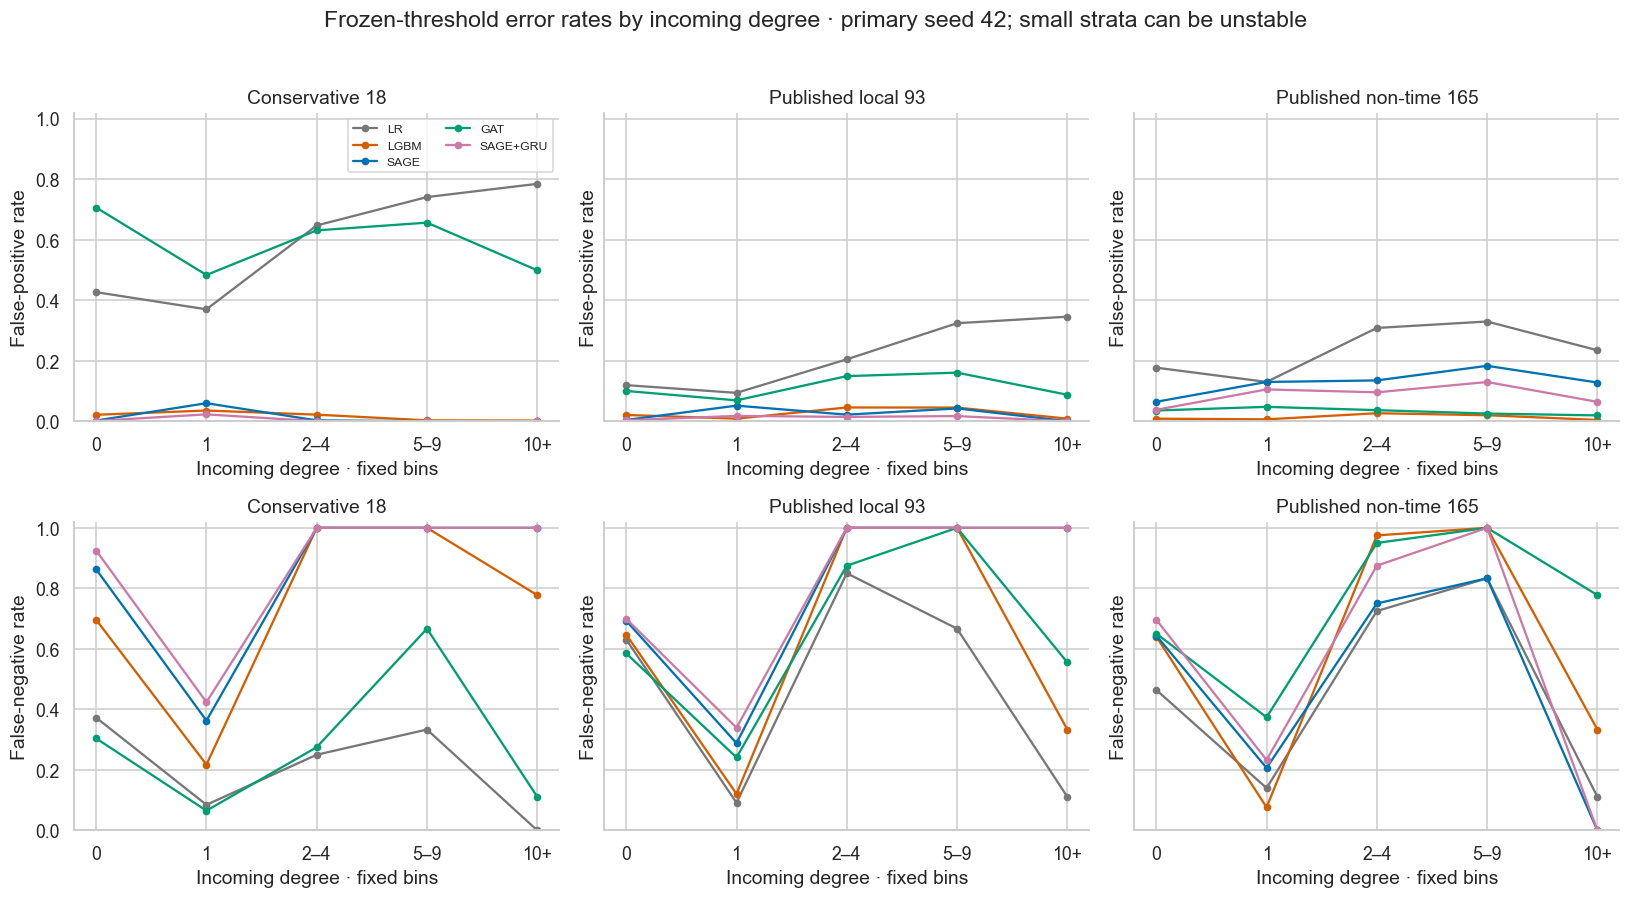

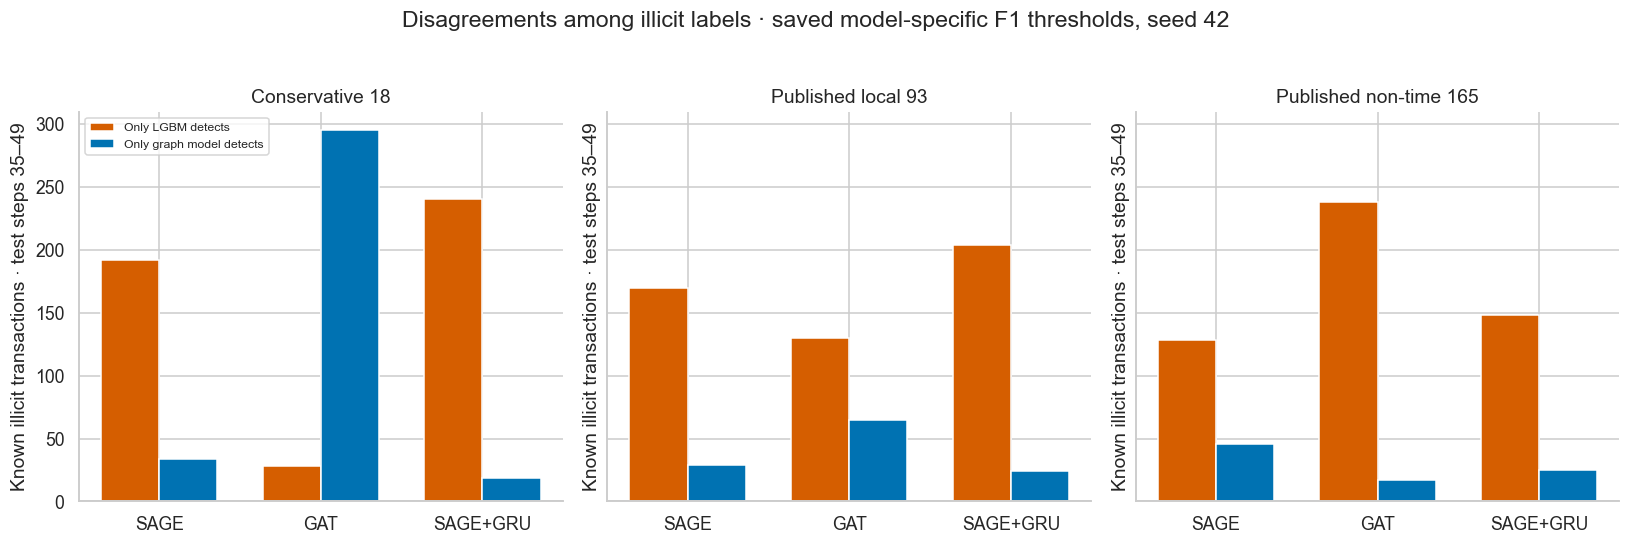

In [10]:
section_start = time.perf_counter()
lookup = nodes.set_index("tx_id")
error_records, disagreement_records, confidence_records = [], [], []
for record in model_records:
    if record["seed"] != PRIMARY_SEED:
        continue
    model_id = record["model_id"]
    frame = raw_predictions.loc[raw_predictions.model_name == model_id + "__raw"].copy()
    aligned = lookup.loc[frame.transaction_id]
    index = aligned.node_index.to_numpy()
    frame["in_degree"] = graph_arrays["indegree"][index]
    frame["out_degree"] = graph_arrays["outdegree"][index]
    frame["component_size"] = graph_arrays["component_size"][index]
    threshold = bundles[model_id]["raw_thresholds"]["f1_threshold"]
    frame["predicted_positive"] = frame.predicted_probability >= threshold
    frame["false_positive"] = frame.predicted_positive & frame.true_label.eq(0)
    frame["false_negative"] = ~frame.predicted_positive & frame.true_label.eq(1)
    for stratifier in ["in_degree", "out_degree"]:
        bins = pd.cut(frame[stratifier], [-1,0,1,4,9,np.inf], labels=["0","1","2–4","5–9","10+"])
        for label, part in frame.groupby(bins, observed=True):
            negatives, positives = int(part.true_label.eq(0).sum()), int(part.true_label.sum())
            error_records.append({"model_id": model_id, "architecture": record["architecture"], "feature_configuration": record["feature_configuration"],
                "stratifier": stratifier, "stratum": str(label), "n_labeled": len(part), "n_illicit": positives,
                "false_positive_rate": part.false_positive.sum()/negatives if negatives else np.nan,
                "false_negative_rate": part.false_negative.sum()/positives if positives else np.nan})
    confidence_bins = pd.cut(frame.predicted_probability, [-.0001,.1,.5,.9,1.0001], labels=["0–0.1","0.1–0.5","0.5–0.9","0.9–1"])
    for label, part in frame.groupby(confidence_bins, observed=True):
        confidence_records.append({"architecture": record["architecture"], "feature_configuration": record["feature_configuration"],
            "probability_band": str(label), "n_labeled": len(part), "observed_illicit_fraction": part.true_label.mean(),
            "mean_probability": part.predicted_probability.mean(), "false_positives": int(part.false_positive.sum()), "false_negatives": int(part.false_negative.sum()),
            "mean_component_size": part.component_size.mean()})
for group in FEATURE_GROUPS:
    lgbm_record = next(r for r in model_records if r["architecture"] == "lightgbm" and r["feature_configuration"] == group)
    lgbm = raw_predictions.loc[raw_predictions.model_name == lgbm_record["model_id"] + "__raw"]
    for architecture in ["graphsage", "gat", "sage_gru"]:
        other_record = next(r for r in model_records if r["architecture"] == architecture and r["feature_configuration"] == group and r["seed"] == PRIMARY_SEED)
        other = raw_predictions.loc[raw_predictions.model_name == other_record["model_id"] + "__raw"]
        first, second = aligned_pair(lgbm, other)
        lgbm_right = (first.predicted_probability >= bundles[lgbm_record["model_id"]]["raw_thresholds"]["f1_threshold"]).to_numpy() == first.true_label.to_numpy()
        other_right = (second.predicted_probability >= bundles[other_record["model_id"]]["raw_thresholds"]["f1_threshold"]).to_numpy() == second.true_label.to_numpy()
        for label in [0,1]:
            mask = first.true_label.to_numpy() == label
            disagreement_records.append({"feature_configuration": group, "other_architecture": architecture, "true_class": label,
                "both_correct": int((mask & lgbm_right & other_right).sum()), "only_lightgbm_correct": int((mask & lgbm_right & ~other_right).sum()),
                "only_graph_correct": int((mask & ~lgbm_right & other_right).sum()), "both_wrong": int((mask & ~lgbm_right & ~other_right).sum())})
errors = save_table(pd.DataFrame(error_records), "degree_error_analysis.csv")
disagreements = save_table(pd.DataFrame(disagreement_records), "model_disagreements.csv")
save_table(pd.DataFrame(confidence_records), "confidence_error_analysis.csv")
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)
for column, group in enumerate(FEATURE_GROUPS):
    for row, (metric, ylabel) in enumerate([("false_positive_rate", "False-positive rate"), ("false_negative_rate", "False-negative rate")]):
        ax = axes[row,column]
        for architecture in ARCHITECTURES:
            view = errors.loc[(errors.feature_configuration == group) & (errors.architecture == architecture) & (errors.stratifier == "in_degree")]
            ax.plot(view.stratum, view[metric], marker="o", ms=4, color=COLORS[architecture], label=SHORT[architecture])
        ax.set(title=GROUP_NAMES[group], xlabel="Incoming degree · fixed bins", ylabel=ylabel, ylim=(0,1.02))
axes[0,0].legend(fontsize=8, ncol=2)
fig.suptitle("Frozen-threshold error rates by incoming degree · primary seed 42; small strata can be unstable", y=1.02)
save_figure(fig, "stage4_13_error_by_degree")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
for ax, group in zip(axes, FEATURE_GROUPS):
    view = disagreements.loc[(disagreements.feature_configuration == group) & (disagreements.true_class == 1)]
    x = np.arange(len(view))
    ax.bar(x-.18, view.only_lightgbm_correct, width=.36, color=COLORS["lightgbm"], label="Only LGBM detects")
    ax.bar(x+.18, view.only_graph_correct, width=.36, color="#0072B2", label="Only graph model detects")
    ax.set(title=GROUP_NAMES[group], xticks=x, xticklabels=[SHORT[a] for a in view.other_architecture], ylabel="Known illicit transactions · test steps 35–49")
axes[0].legend(fontsize=8)
fig.suptitle("Disagreements among illicit labels · saved model-specific F1 thresholds, seed 42", y=1.03)
save_figure(fig, "stage4_14_illicit_disagreements")
save_progress("aggregate_error_analysis", time.perf_counter() - section_start)

**Observed errors.** The disagreement counts identify illicit transactions detected by only one model at its saved threshold, alongside substantial model-specific misses. Sparse high-degree strata can yield extreme error rates. Different thresholds and selective labels preclude interpreting these counts as operational review gains.

Feature-group comparisons can change both ranking and operating thresholds. A model detecting some positives missed by LightGBM does not by itself justify an ensemble; no ensemble or threshold change is selected here. Each released snapshot is connected as one weak component, so component membership provides little within-snapshot segmentation in this dataset.

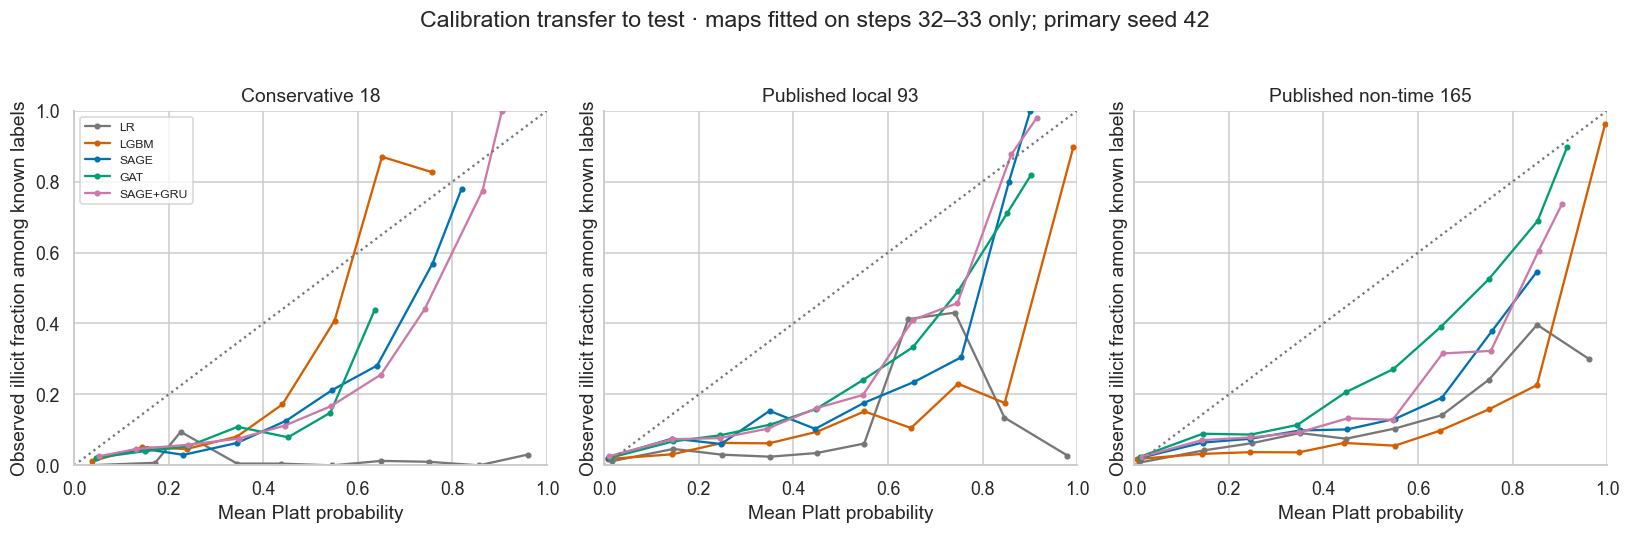

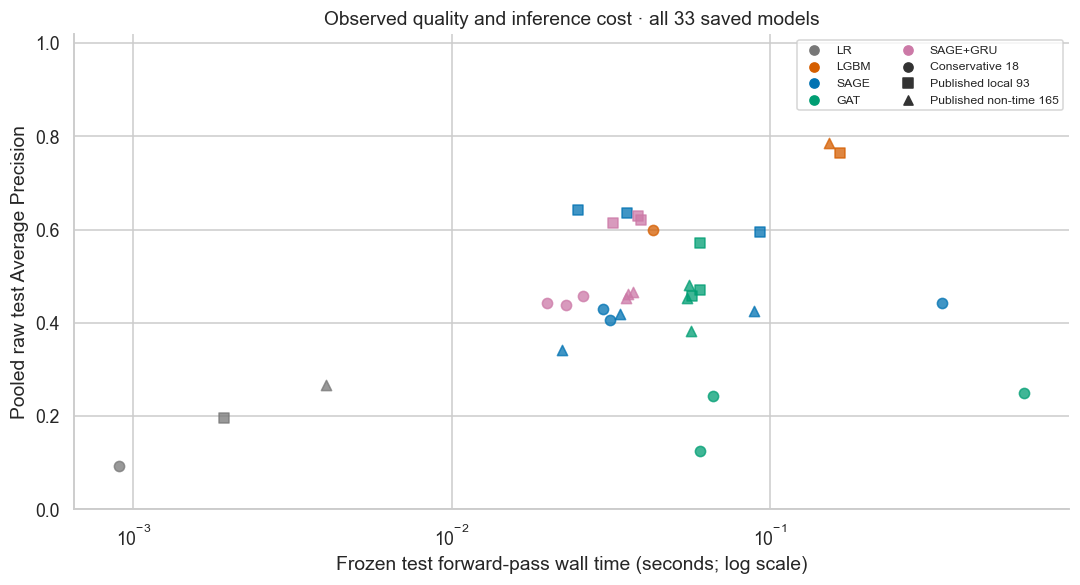

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.7), sharey=True)
for ax, group in zip(axes, FEATURE_GROUPS):
    for architecture in ARCHITECTURES:
        record = next(r for r in model_records if r["architecture"] == architecture and r["feature_configuration"] == group and r["seed"] == PRIMARY_SEED)
        frame = platt_predictions.loc[platt_predictions.model_name == record["model_id"] + "__platt"]
        fraction, mean = calibration_curve(frame.true_label, frame.predicted_probability, n_bins=CALIBRATION_BINS, strategy="uniform")
        ax.plot(mean, fraction, marker="o", ms=3, color=COLORS[architecture], label=SHORT[architecture])
    ax.plot([0,1],[0,1], color="#777777", ls=":")
    ax.set(title=GROUP_NAMES[group], xlabel="Mean Platt probability", ylabel="Observed illicit fraction among known labels", xlim=(0,1), ylim=(0,1))
axes[0].legend(fontsize=8)
fig.suptitle("Calibration transfer to test · maps fitted on steps 32–33 only; primary seed 42", y=1.03)
save_figure(fig, "stage4_15_calibration_transfer")

fig, ax = plt.subplots(figsize=(10, 5.5))
for record in model_records:
    row = raw_metrics.loc[raw_metrics.model_id == record["model_id"]].iloc[0]
    runtime = runtimes.loc[runtimes.model_id == record["model_id"]].iloc[0]
    ax.scatter(runtime.inference_seconds, row.average_precision, color=COLORS[record["architecture"]],
        marker={"conservative18":"o", "local93":"s", "published165":"^"}[record["feature_configuration"]], alpha=.75, s=45)
for architecture in ARCHITECTURES:
    ax.scatter([], [], color=COLORS[architecture], label=SHORT[architecture])
for group, marker in zip(FEATURE_GROUPS, ["o","s","^"]):
    ax.scatter([], [], color="#333333", marker=marker, label=GROUP_NAMES[group])
ax.set(xscale="log", xlabel="Frozen test forward-pass wall time (seconds; log scale)", ylabel="Pooled raw test Average Precision", title="Observed quality and inference cost · all 33 saved models", ylim=(0,1.02))
ax.legend(fontsize=8, ncol=2)
save_figure(fig, "stage4_16_quality_inference_cost")

**Observed calibration and cost.** Saved Platt scaling lowers mean neural Brier scores for all nine settings, but raises LightGBM Brier for 93/165 features and local-93 logistic regression. Calibration transfer is not uniformly beneficial. Forward-pass timings use mixed validated hardware, include first-call effects and exclude graph construction and GRU history reconstruction; they do not establish an operational speed ranking.

## 10. Key Research Findings and Limitations
The tables below are generated from saved predictions and cached experiments. They describe this historical benchmark and modest trained architectures, not deployment effectiveness or a definitive ranking of model families.

In [12]:
lines = []
for group in FEATURE_GROUPS:
    view = summary.loc[summary.feature_configuration == group].set_index("architecture")
    text = "; ".join(f"{SHORT[a]} AP **{view.loc[a,'ap_mean']:.4f}**" + (f" ± {view.loc[a,'ap_seed_sd']:.4f} seed SD" if view.loc[a,'seeds'] > 1 else "") for a in ARCHITECTURES)
    lines.append(f"- **{GROUP_NAMES[group]}:** {text}.")
lines.extend(["- Seed variability and temporal-block intervals address different uncertainty sources; neither resolves selective labels or source leakage.",
    "- Feature and score shifts do not establish concept drift or the cause of a historical event.",
    "- The temporal head changes shared snapshot logit levels; it does not isolate historical ranking value.",
    "- Nineteen earlier fits reached the training cap; no capped model was retrained after test access.",
    "- Edge perturbations leave precomputed neighborhood features unchanged; this is structural sensitivity, not a realistic transaction simulation."])
if QUICK_RUN:
    lines.insert(0, "**QUICK_RUN: exploratory review of cached official results; no new official test experiment.**")
display(Markdown("\n".join(lines)))
verify_frozen(ROOT, PROTOCOL_PATH, protocol_hash)
execution = {"stage": 4, "run_mode": RUN_MODE, "exploratory": QUICK_RUN, "protocol_sha256": protocol_hash,
    "reused_models": len(model_records), "tabular_models": 6, "neural_models": 27, "neural_seeds": SEEDS,
    "test_labeled": len(known_test), "test_illicit": int(known_test.target.sum()),
    "new_model_fits": 0, "new_calibrator_fits": 0, "test_threshold_selections": 0,
    "prediction_rows_per_variant": len(raw_predictions), "robustness_rows": len(robustness),
    "bootstrap_replications": BOOTSTRAP_REPETITIONS, "new_figures": figure_names,
    "seconds": round(time.perf_counter() - started_at, 3), "sections": section_times,
    "mps_available": torch.backends.mps.is_available(), "cpu_threads": CPU_THREADS,
    "actual_devices": {a: sorted({devices[r["model_id"]] for r in model_records if r["architecture"] == a}) for a in ARCHITECTURES},
    "versions": {name: importlib.metadata.version(name) for name in ["torch","torch-geometric","scikit-learn","lightgbm","numpy","pandas","scipy"]},
    "stage5_started": False}
(RESULT_DIR / "execution_summary.json").write_text(json.dumps(execution, indent=2, allow_nan=False) + "\n")
print("Completed frozen-model evaluation. Notebook runtime (seconds):", execution["seconds"])

- **Conservative 18:** LR AP **0.0922**; LGBM AP **0.5993**; SAGE AP **0.4263** ± 0.0194 seed SD; GAT AP **0.2059** ± 0.0699 seed SD; SAGE+GRU AP **0.4466** ± 0.0101 seed SD.
- **Published local 93:** LR AP **0.1956**; LGBM AP **0.7639**; SAGE AP **0.6246** ± 0.0254 seed SD; GAT AP **0.5000** ± 0.0618 seed SD; SAGE+GRU AP **0.6211** ± 0.0082 seed SD.
- **Published non-time 165:** LR AP **0.2664**; LGBM AP **0.7866**; SAGE AP **0.3953** ± 0.0463 seed SD; GAT AP **0.4387** ± 0.0507 seed SD; SAGE+GRU AP **0.4599** ± 0.0069 seed SD.
- Seed variability and temporal-block intervals address different uncertainty sources; neither resolves selective labels or source leakage.
- Feature and score shifts do not establish concept drift or the cause of a historical event.
- The temporal head changes shared snapshot logit levels; it does not isolate historical ranking value.
- Nineteen earlier fits reached the training cap; no capped model was retrained after test access.
- Edge perturbations leave precomputed neighborhood features unchanged; this is structural sensitivity, not a realistic transaction simulation.

Completed frozen-model evaluation. Notebook runtime (seconds): 166.007
